# Cross-disease comparison of drug rankings

Proof of concept on the **unfiltered** drug rankings: for a fixed scoring method, the drug rankings that the
method returns for different diseases are compared with each other. If rankings of distant diseases agree, part
of the ordering depends on the **drug** and not on the disease.

**Diseases (6).** Asthma (GSE152004), IPF, ALS (NYGC), and three TCGA cancers (BRCA, LIHC, COAD).
**Methods (models).** Each (configuration, score type) is a separate model, and a median over models summarises them.
The input ranking table is a parameter of the first code cell, so the same notebook can be run on another ranking table.

## Definitions

Terms as computed in this notebook; the score of every drug is a connectivity score (CS), most negative = strongest predicted reversal of the disease signature.

| Term | What it is | Where computed |
|---|---|---|
| **Model** | One drug ranking of one method, e.g. `DEG_sRGES`: configuration (`DEG`, `DEG_LM`, `mith`, `mith_LM`, `mith_pw`) + score type. Each model has one score per drug and disease. | section 1 |
| **Per-instance route** | Score types `sRGES`, `wsRGES`, `best`: the CS of each LINCS instance (drug, cell line, dose, time) is computed first, then summarised per drug: `sRGES` = unweighted sRGES over lines, `wsRGES` = sRGES weighted by cell-line similarity to the disease, `best` = most negative CS. | `src/case_study/per_drug_scores.py`, `src/validations/chembl/wsRGES_IC50_correlations.py` |
| **TSR route** | Score type `TSR` (transcriptome signature reversion): the drug signature is summarised across instances before the CS (LMM, `tsr/`); pooled 6 h + 24 h score. | `src/case_study/known_drugs.py` |
| **Drug key** | Compound name in lower case, alphanumerics only; drugs are joined across diseases on this key; duplicated keys take the mean score. | `src/case_study/known_drugs.py::key` |
| **Universe** | The set of drugs scored in a model and disease. | section 1 |
| **Percentile** | `rank(score) / n x 100` within the model and disease (average rank of ties); 0-100, low = strong reversal. Recomputed here from the score. | section 1 |
| **Shared drugs** | Drugs scored in both diseases of a pair (and in the variant's subset); `n` is their count. | section 2 |
| **Spearman rho** | Rank correlation of the two CS vectors over the shared drugs, in [-1, 1]. | section 2 |
| **Top-k set** | The k shared drugs with the most negative CS in a disease (ranked after restricting to the shared drugs); k = 50, 100 and 5% of the shared drugs. | section 2 |
| **Jaccard J** | J = abs(A intersect B) / abs(A union B) of two top-k sets; with overlap x = abs(A intersect B), J = x / (2k - x). 0 = disjoint, 1 = identical. | section 2 |
| **Null Jaccard** | Expected J for two random top-k sets drawn from the same N shared drugs: x is hypergeometric(N, k, k), null = E[x / (2k - x)]; `p_overlap` = P(X >= x observed). | section 2 |
| **n_instances** | Number of LINCS instances (dose > 0, 6 h or 24 h) a per-instance score averages; undefined for TSR. | per-instance tables |
| **ge3inst variant** | Shared drugs with n_instances >= 3 in both diseases (per-instance models only). | section 3 |
| **no_cortico variant** | Corticosteroids (list in section 3) removed. | section 3 |
| **Fisher-z mean** | Mean of atanh(rho) over models, back-transformed with tanh. | section 2.1 |
| **J / J_expected** | Jaccard index of a model divided by its hypergeometric null Jaccard for the same pair; 1 = chance; averaged over models in place of the raw J. | section 2.1 |
| **DEG family / MITHrIL family** | Models with configuration `DEG`, `DEG_LM` / `mith`, `mith_LM`, `mith_pw`. | section 2.3 |
| **Flagged (model)** | A drug whose mean percentile across the diseases is <= `MEAN_MAX` and whose SD of percentile across the diseases is <= `SD_MAX`, in one model. | section 4 |
| **Flagged drug** | A drug flagged in at least a fraction `FLAG_FRAC` of the models of a family (thresholds in the parameter cell). The label is descriptive: it implies no drug-specific property beyond the threshold. | section 4 |

In [1]:
import sys, os
from pathlib import Path
from itertools import combinations
from types import SimpleNamespace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, hypergeom
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path(os.getcwd()).resolve(), *Path(os.getcwd()).resolve().parents] if (p / 'src' / 'conf.py').exists())
sys.path.insert(0, str(ROOT / 'src'))
import conf
from loader import load_cs_run
import lfs_style
lfs_style.apply()
from case_study.known_drugs import key, split_pert_id, add_ranks, per_instance_rankings, TSR_CONFIGS

# ----------------------------- parameters -----------------------------
SLUG = 'cross_disease'
RANKINGS_NAME = 'drug_rankings'         # reads <case>/<case>_<RANKINGS_NAME>.tsv
TAG = ''                                # suffix of every output file name
CASES = {'asthma': 'asthma_GSE152004', 'IPF': 'ipf', 'ALS': 'als_NYGC'}
TCGA_TABLE = conf.BINCHEN_VALIDATION_OUT_DIR / 'tcga_wsRGES_per_drug_corrected.tsv'   # None = no TCGA diseases
TCGA_COLLAPSES = {'sRGES_all': 'sRGES', 'wsRGES': 'wsRGES', 'best_all': 'best'}
SCORE_TYPES = ['sRGES', 'wsRGES', 'best', 'TSR']
DISEASES = ['asthma', 'IPF', 'ALS', 'BRCA', 'LIHC', 'COAD']
CANCERS = {'BRCA', 'LIHC', 'COAD'}
DIFF_MODE = {'case study': 'corrected', 'TCGA': 'corrected'}   # srges_diff_mode of the per-instance scores
TOP_K = [50, 100]                       # plus TOP_FRAC of the shared drugs
TOP_FRAC = 0.05
MIN_INSTANCES = 3
MEAN_MAX, SD_MAX = 10.0, 10.0           # per model: mean and SD of percentile across diseases
FLAG_FRAC = 0.25                        # a drug is listed as flagged if flagged in at least this fraction of the models of a family
N_PERM = 1000
SEED = 0

OUT_IMG = conf.IMG_DIR / 'case_studies' / SLUG
OUT_TAB = conf.OOUT_DIR / 'case_studies' / SLUG
OUT_IMG.mkdir(parents=True, exist_ok=True); OUT_TAB.mkdir(parents=True, exist_ok=True)
REL_IMG = f'../../../imgs/case_studies/{SLUG}'   # image links of the exported report
_tn = [0]; _fn = [0]

def md_table(df, fmt='{:.3f}', index=False):
    df = df.reset_index() if index else df
    cols = list(df.columns)
    def f(v):
        if isinstance(v, (float, np.floating)):
            return '' if np.isnan(v) else (fmt.format(v) if not float(v).is_integer() or abs(v) < 1 else f'{v:.0f}')
        return str(v)
    lines = ['| ' + ' | '.join(map(str, cols)) + ' |', '|' + '---|' * len(cols)]
    lines += ['| ' + ' | '.join(f(v) for v in r) + ' |' for r in df.itertuples(index=False)]
    return '\n'.join(lines)

def show_table(df, caption, fmt='{:.3f}', index=False):
    _tn[0] += 1
    display(Markdown(f'**Table {_tn[0]}.** {caption}\n\n' + md_table(df, fmt, index)))

def show_fig(fig, name, caption):
    _fn[0] += 1
    fn = f'{SLUG}_{name}{TAG}.png'
    fig.savefig(OUT_IMG / fn, dpi=200, bbox_inches='tight'); plt.close(fig)
    display(Image(filename=str(OUT_IMG / fn)))   # inline in the notebook; the Markdown link below serves the exported report
    display(Markdown(f'![Figure {_fn[0]}]({REL_IMG}/{fn})\n\n**Figure {_fn[0]}.** {caption}'))

def save(df, name):
    df.to_csv(OUT_TAB / f'{SLUG}_{name}{TAG}.tsv', sep='\t', index=False)
N_MARK = 100                            # cells with fewer shared drugs are marked (hatched) in the grid figures


## 1. Input rankings

Each case-study ranking table (`<case>_<RANKINGS_NAME>.tsv`) has one row per (ranking, drug). Models kept: per-instance
score types `sRGES`, `wsRGES`, `best` and the pooled `TSR`; the top-line collapses (`*_topMed`) exist for some diseases only and
are left out. The TCGA diseases enter through the per-drug table `tcga_wsRGES_per_drug_corrected.tsv` (written by `src/validations/chembl/wsRGES_tcga_corrected_offsets.py` from the per-instance CS runs of the Chen 2017 validation: per-instance CS on all 71 lines,
same sRGES / wsRGES / best collapses); no TSR run on the LMM library exists for them. The per-instance scores of all six diseases use the same dose/time offset assignment (`srges_diff_mode = "corrected"`). They differ in the origin of the wsRGES cell-line weights (TCGA tumours vs DepMap lines for the cancers; the disease's own samples for asthma, IPF and ALS) and in the dates of the CS runs (12-14/11/2026 for the cancers, 17-18/11/2026 for asthma, IPF and ALS) (Table 1). `best` does not depend on the offsets.
The drug-level percentile is recomputed from the score within each model and disease.

In [2]:
USE = ['ranking', 'config', 'collapse', 'drug_key', 'score', 'n_instances', 'cs_run_id']
COLL = {'pooled': 'TSR', 'sRGES': 'sRGES', 'wsRGES': 'wsRGES', 'best': 'best'}

def build_case(slug):
    # reconstruct the unfiltered ranking of a case study without <slug>_drug_rankings.tsv
    # (same recipe as src/case_study/known_drugs.py)
    d = conf.OOUT_DIR / 'case_studies' / slug
    pi, meta = per_instance_rankings(SimpleNamespace(oout_dir=d, slug=slug))
    rows = [r.assign(ranking=n, config=meta[n][0], collapse=meta[n][1]) for n, r in pi.items()]
    for label, (m, lm, pw) in TSR_CONFIGS.items():
        try:
            df, path, run_id = load_cs_run(disease=slug, landmark_disease=False, drug_run_id='all', mith=m, cs_on_LM=lm,
                                           CS_ON_PATHWAYS=pw, CS_METHOD='bin_chen', verbose=False)
        except FileNotFoundError:
            continue
        dt = df['pert_id'].astype(str).map(split_pert_id)
        df = df.assign(drug=dt.str[0], tp=dt.str[1])
        df['drug_key'] = key(df['drug'])
        g = df[df['tp'] == '6h_24h'].groupby('drug_key')['connectivity_score'].mean().rename('score').reset_index()
        rows.append(g.assign(ranking=f'{label}_TSR', config=label, collapse='pooled', cs_run_id=run_id))
    return pd.concat(rows, ignore_index=True).reindex(columns=USE)

parts, sources = [], []
for dis, slug in CASES.items():
    p = conf.OOUT_DIR / 'case_studies' / slug / f'{slug}_{RANKINGS_NAME}.tsv'
    if p.exists():
        d = pd.read_csv(p, sep='\t', usecols=USE, low_memory=False); src = p.name
    elif RANKINGS_NAME == 'drug_rankings':
        d = build_case(slug); src = f'{slug}_srges_per_drug.tsv + drug-collapsed CS runs (reconstructed, {slug}_drug_rankings.tsv absent)'
    else:
        print('missing', p); continue
    parts.append(d.assign(disease=dis)); sources.append((dis, src))
if TCGA_TABLE is not None and Path(TCGA_TABLE).exists():
    t = pd.read_csv(TCGA_TABLE, sep='\t')
    t = t[t['collapse'].isin(TCGA_COLLAPSES)].copy()
    t['drug_key'] = key(t['pert_iname'])
    t = t.groupby(['cancer', 'config', 'collapse', 'drug_key']).agg(score=('score', 'mean'), n_instances=('n_instances', 'sum')).reset_index()
    t['cs_run_id'] = np.nan
    t['collapse'] = t['collapse'].map(TCGA_COLLAPSES)
    t['ranking'] = t['config'] + '_' + t['collapse']
    for c, d in t.groupby('cancer'):
        parts.append(d.drop(columns='cancer').assign(disease=c)); sources.append((c, Path(TCGA_TABLE).name))
R = pd.concat(parts, ignore_index=True)
R = R[R['collapse'].isin(COLL)].copy()
R['score_type'] = R['collapse'].map(COLL)
R['family'] = np.where(R['score_type'] == 'TSR', 'TSR', 'per-instance')
R = R.rename(columns={'ranking': 'model'})
dup = R.duplicated(['disease', 'model', 'drug_key']).sum()
assert dup == 0, dup
R['pct'] = R.groupby(['disease', 'model'])['score'].rank(pct=True) * 100
R['disease'] = pd.Categorical(R['disease'], DISEASES, ordered=True)
dis_present = [d for d in DISEASES if d in set(R['disease'])]

def _dates(ids):
    d = pd.to_datetime(pd.Series(list(ids)).astype(str).str.extract(r'^(\d{2}_\d{2}_\d{4})')[0], format='%d_%m_%Y').dropna()
    if d.empty: return ''
    return d.min().strftime('%d/%m/%Y') + ('' if d.min() == d.max() else ' - ' + d.max().strftime('%d/%m/%Y'))
rows = []
for (dis, src) in sources:
    if dis in CASES:
        ru = pd.read_csv(conf.OOUT_DIR / 'case_studies' / CASES[dis] / f'{CASES[dis]}_srges_cs_runs_used.tsv', sep='\t')
        mode, wsrc = DIFF_MODE['case study'], 'similarity of the LINCS lines to the disease samples (own signature)'
    else:
        ru = pd.read_csv(conf.BINCHEN_VALIDATION_OUT_DIR / 'tcga_wsRGES_cs_runs_used.tsv', sep='\t'); ru = ru[ru['cancer'] == dis]
        mode, wsrc = DIFF_MODE['TCGA'], 'similarity of the DepMap lines to TCGA tumours (per cancer)'
    tsr = _dates(R.loc[(R['disease'] == dis) & (R['family'] == 'TSR'), 'cs_run_id'].dropna().unique())
    rows.append({'disease': dis, 'source of scores': src, 'srges_diff_mode': mode, 'wsRGES weights': wsrc,
                 'per-instance CS runs': _dates(ru['cs_run_id'].unique()), 'TSR CS runs': tsr or 'none'})
src_df = pd.DataFrame(rows)
show_table(src_df, 'Source of the drug scores of each disease (files in `other_outputs/`), offset assignment (`srges_diff_mode`), origin of the wsRGES cell-line weights, and dates of the per-instance and TSR connectivity-score runs (dd/mm/yyyy, from the run identifiers). The wsRGES weight source differs between the cancers and the other diseases.')
u = R.groupby(['family', 'disease', 'model'], observed=True).size().rename('n_drugs').reset_index()
uu = u.groupby(['family', 'disease'], observed=True)['n_drugs'].agg(['count', 'min', 'max']).reset_index()
uu.columns = ['family', 'disease', 'n_models', 'min_n_drugs', 'max_n_drugs']
show_table(uu, 'Models and universe size per family and disease: number of models and the smallest and largest number of drugs scored in a model (count of compounds).')

**Table 1.** Source of the drug scores of each disease (files in `other_outputs/`), offset assignment (`srges_diff_mode`), origin of the wsRGES cell-line weights, and dates of the per-instance and TSR connectivity-score runs (dd/mm/yyyy, from the run identifiers). The wsRGES weight source differs between the cancers and the other diseases.

| disease | source of scores | srges_diff_mode | wsRGES weights | per-instance CS runs | TSR CS runs |
|---|---|---|---|---|---|
| asthma | asthma_GSE152004_srges_per_drug.tsv + drug-collapsed CS runs (reconstructed, asthma_GSE152004_drug_rankings.tsv absent) | corrected | similarity of the LINCS lines to the disease samples (own signature) | 17/11/2026 - 18/11/2026 | 27/10/2026 |
| IPF | ipf_drug_rankings.tsv | corrected | similarity of the LINCS lines to the disease samples (own signature) | 17/11/2026 - 18/11/2026 | 21/06/2026 - 30/06/2026 |
| ALS | als_NYGC_drug_rankings.tsv | corrected | similarity of the LINCS lines to the disease samples (own signature) | 17/11/2026 - 18/11/2026 | 30/06/2026 |
| BRCA | tcga_wsRGES_per_drug_corrected.tsv | corrected | similarity of the DepMap lines to TCGA tumours (per cancer) | 12/11/2026 - 14/11/2026 | none |
| COAD | tcga_wsRGES_per_drug_corrected.tsv | corrected | similarity of the DepMap lines to TCGA tumours (per cancer) | 12/11/2026 - 14/11/2026 | none |
| LIHC | tcga_wsRGES_per_drug_corrected.tsv | corrected | similarity of the DepMap lines to TCGA tumours (per cancer) | 12/11/2026 - 14/11/2026 | none |

**Table 2.** Models and universe size per family and disease: number of models and the smallest and largest number of drugs scored in a model (count of compounds).

| family | disease | n_models | min_n_drugs | max_n_drugs |
|---|---|---|---|---|
| TSR | asthma | 5 | 3221 | 3221 |
| TSR | IPF | 5 | 3221 | 3221 |
| TSR | ALS | 5 | 3221 | 3221 |
| per-instance | asthma | 12 | 12419 | 12440 |
| per-instance | IPF | 12 | 12419 | 12440 |
| per-instance | ALS | 12 | 12419 | 12440 |
| per-instance | BRCA | 12 | 12166 | 12440 |
| per-instance | LIHC | 12 | 12166 | 12440 |
| per-instance | COAD | 12 | 12166 | 12440 |

In [3]:
# models available per family: those scored in at least two diseases
sl = R.groupby(['family', 'model'], observed=True)['disease'].agg(lambda s: tuple(sorted(set(s.astype(str)), key=DISEASES.index))).reset_index()
sl = sl[sl['disease'].map(len) >= 2].copy()
sl['config'] = sl['model'].str.replace(r'_(sRGES|wsRGES|best|TSR)$', '', regex=True)
sl['score_type'] = sl['model'].str.extract(r'_(sRGES|wsRGES|best|TSR)$')[0]
sl['n_diseases'] = sl['disease'].map(len)
show_table(sl.assign(diseases=sl['disease'].map(', '.join)).drop(columns='disease')[['family', 'model', 'config', 'score_type', 'n_diseases', 'diseases']],
           'Models compared: family, model name, configuration, score type, and the diseases in which the model is scored.')

**Table 3.** Models compared: family, model name, configuration, score type, and the diseases in which the model is scored.

| family | model | config | score_type | n_diseases | diseases |
|---|---|---|---|---|---|
| TSR | DEG_LM_TSR | DEG_LM | TSR | 3 | asthma, IPF, ALS |
| TSR | DEG_TSR | DEG | TSR | 3 | asthma, IPF, ALS |
| TSR | mith_LM_TSR | mith_LM | TSR | 3 | asthma, IPF, ALS |
| TSR | mith_TSR | mith | TSR | 3 | asthma, IPF, ALS |
| TSR | mith_pw_TSR | mith_pw | TSR | 3 | asthma, IPF, ALS |
| per-instance | DEG_best | DEG | best | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |
| per-instance | DEG_sRGES | DEG | sRGES | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |
| per-instance | DEG_wsRGES | DEG | wsRGES | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |
| per-instance | mith_LM_best | mith_LM | best | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |
| per-instance | mith_LM_sRGES | mith_LM | sRGES | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |
| per-instance | mith_LM_wsRGES | mith_LM | wsRGES | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |
| per-instance | mith_best | mith | best | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |
| per-instance | mith_pw_best | mith_pw | best | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |
| per-instance | mith_pw_sRGES | mith_pw | sRGES | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |
| per-instance | mith_pw_wsRGES | mith_pw | wsRGES | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |
| per-instance | mith_sRGES | mith | sRGES | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |
| per-instance | mith_wsRGES | mith | wsRGES | 6 | asthma, IPF, ALS, BRCA, LIHC, COAD |

## 2. Pairwise agreement per model

For each model and each pair of diseases, on the shared drugs: Spearman rho of the CS, and the Jaccard index of the top-k sets
(k = 50, 100, 5% of the shared drugs; top = most negative CS). The null Jaccard is the hypergeometric expectation for random top-k sets of the same
size drawn from the same shared drugs. Pair classes: *cancer-cancer* (BRCA, LIHC, COAD), *non-cancer* (asthma, IPF, ALS), *cancer vs non-cancer*.

In [4]:
CORTICO = ['dexamethasone', 'prednisolone', 'prednisone', 'hydrocortisone', 'betamethasone', 'triamcinolone', 'budesonide',
           'methylprednisolone', 'clobetasol', 'corticosterone', 'cortisone', 'fludrocortisone', 'beclomethasone',
           'mometasone', 'flumethasone', 'halcinonide', 'fluorometholone', 'flunisolide', 'deflazacort', 'clocortolone',
           'desoximetasone', 'fluticasone', 'amcinonide', 'halobetasol', 'loteprednol', 'medrysone', 'paramethasone',
           'prednicarbate', 'rimexolone', 'alclometasone', 'diflorasone', 'difluprednate', 'fluocinonide', 'fluocortolone',
           'fluocinolone', 'fluprednidene', 'cortisol', 'meprednisone', 'prednylidene', 'triamcinolonediacetate',
           'dexamethasoneacetate', 'hydrocortisoneacetate', 'betamethasonevalerate', 'fluclorolone', 'flurandrenolide',
           'fluocinoloneacetonide', 'triamcinoloneacetonide', 'halometasone', 'cortivazol', 'flumetasone',
           'betamethasonedipropionate', 'betamethasoneacetate']
CORTICO = set(key(CORTICO))
univ = set(R['drug_key'])
matched = sorted(CORTICO & univ)
cs_tab = R[R['drug_key'].isin(matched)].groupby('drug_key', observed=True).agg(n_diseases=('disease', lambda s: s.nunique()), n_rows=('score', 'size'),
                                                                   median_percentile=('pct', 'median')).reset_index()
show_table(cs_tab, f'Corticosteroids of the list found among the scored drugs (n = {len(matched)} of {len(CORTICO)} names); number of diseases and of (model, disease) rows in which each is scored, and median percentile over those rows (0-100, low = strong reversal).', fmt='{:.1f}')

**Table 4.** Corticosteroids of the list found among the scored drugs (n = 38 of 52 names); number of diseases and of (model, disease) rows in which each is scored, and median percentile over those rows (0-100, low = strong reversal).

| drug_key | n_diseases | n_rows | median_percentile |
|---|---|---|---|
| alclometasone | 6 | 87 | 50.2 |
| amcinonide | 6 | 87 | 53.8 |
| betamethasone | 6 | 87 | 44.8 |
| betamethasoneacetate | 3 | 15 | 30.1 |
| budesonide | 6 | 87 | 38.7 |
| clobetasol | 6 | 87 | 32.6 |
| clocortolone | 6 | 72 | 48.2 |
| corticosterone | 6 | 72 | 36.2 |
| cortisol | 6 | 72 | 87.0 |
| cortisone | 6 | 87 | 44.2 |
| deflazacort | 6 | 72 | 75.0 |
| desoximetasone | 6 | 87 | 28.9 |
| dexamethasone | 6 | 87 | 49.8 |
| dexamethasoneacetate | 3 | 15 | 60.5 |
| diflorasone | 6 | 87 | 45.5 |
| fludrocortisone | 6 | 72 | 42.0 |
| flumetasone | 6 | 87 | 42.5 |
| flunisolide | 6 | 87 | 39.7 |
| fluocinolone | 6 | 87 | 38.9 |
| fluocinoloneacetonide | 3 | 15 | 70.5 |
| fluocinonide | 6 | 72 | 48.6 |
| fluorometholone | 6 | 87 | 43.2 |
| flurandrenolide | 6 | 72 | 56.0 |
| fluticasone | 6 | 87 | 36.3 |
| halcinonide | 6 | 87 | 47.7 |
| halometasone | 6 | 72 | 41.0 |
| hydrocortisone | 6 | 87 | 41.0 |
| hydrocortisoneacetate | 3 | 15 | 39.9 |
| loteprednol | 6 | 72 | 43.5 |
| medrysone | 6 | 87 | 44.1 |
| methylprednisolone | 6 | 72 | 47.6 |
| mometasone | 6 | 87 | 43.2 |
| prednicarbate | 6 | 87 | 26.0 |
| prednisolone | 6 | 87 | 49.0 |
| prednisone | 6 | 87 | 30.6 |
| rimexolone | 6 | 87 | 42.9 |
| triamcinolone | 6 | 87 | 38.9 |
| triamcinoloneacetonide | 3 | 15 | 63.7 |

In [5]:
_nullcache = {}
def jaccard_null(N, k):
    if (N, k) not in _nullcache:
        x = np.arange(0, k + 1)
        pm = hypergeom.pmf(x, N, k, k)
        _nullcache[(N, k)] = float((pm * x / (2 * k - x)).sum())
    return _nullcache[(N, k)]

def pair_class(a, b):
    ca, cb = a in CANCERS, b in CANCERS
    return 'cancer-cancer' if ca and cb else ('non-cancer' if not ca and not cb else 'cancer vs non-cancer')

def variants_for(family):
    v = ['all', 'no_cortico']
    return (['all', 'ge3inst', 'no_cortico', 'ge3inst_no_cortico'] if family == 'per-instance' else v)

rows_s, rows_j = [], []
for (family, slc), g in R.groupby(['family', 'model'], observed=True):
    sc = g.pivot(index='drug_key', columns='disease', values='score')
    ni = g.pivot(index='drug_key', columns='disease', values='n_instances')
    ds = [d for d in DISEASES if d in sc.columns and sc[d].notna().any()]
    if len(ds) < 2: continue
    for var in variants_for(family):
        for a, b in combinations(ds, 2):
            m = sc[a].notna() & sc[b].notna()
            if 'ge3inst' in var: m &= (ni[a] >= MIN_INSTANCES) & (ni[b] >= MIN_INSTANCES)
            if 'no_cortico' in var: m &= ~sc.index.isin(CORTICO)
            x, y = sc.loc[m, a], sc.loc[m, b]
            n = int(m.sum())
            if n < 10: continue
            rho = spearmanr(x, y).statistic
            base = dict(family=family, model=slc, variant=var, disease_a=a, disease_b=b, pair_class=pair_class(a, b), n_shared=n)
            rows_s.append({**base, 'spearman': rho})
            rx, ry = x.rank(method='first'), y.rank(method='first')
            for lab, k in [(str(kk), kk) for kk in TOP_K] + [(f'{int(TOP_FRAC*100)}pct', max(2, int(round(TOP_FRAC * n))))]:
                if k >= n: continue
                A = set(rx.index[rx <= k]); B = set(ry.index[ry <= k])
                ov = len(A & B)
                rows_j.append({**base, 'k_label': lab, 'k': k, 'overlap': ov, 'jaccard': ov / (2 * k - ov),
                               'jaccard_null': jaccard_null(n, k), 'p_overlap': hypergeom.sf(ov - 1, n, k, k)})
S = pd.DataFrame(rows_s); J = pd.DataFrame(rows_j)
S = S.merge(sl[['model', 'config', 'score_type']], on='model'); J = J.merge(sl[['model', 'config', 'score_type']], on='model')
J['ratio_to_null'] = J['jaccard'] / J['jaccard_null']
save(S, 'pairwise_spearman'); save(J, 'pairwise_jaccard')

In [6]:
def summ(df, col):
    return df.groupby(['family', 'variant', 'pair_class'])[col].agg(['count', 'min', 'median', 'max']).reset_index()

s1 = summ(S[S['variant'] == 'all'], 'spearman')
s1.columns = ['family', 'variant', 'pair_class', 'n (model, pair)', 'min', 'median', 'max']
show_table(s1.drop(columns='variant'), 'Spearman rho (unitless) of the CS on the shared drugs, per family and pair class, over all (model, disease pair) combinations; unfiltered drugs.', fmt='{:.2f}')
j1 = J[(J['variant'] == 'all')].copy()
jj = j1.groupby(['family', 'k_label', 'pair_class']).agg(n=('jaccard', 'size'), jaccard_min=('jaccard', 'min'), jaccard_median=('jaccard', 'median'), jaccard_max=('jaccard', 'max'),
                                                        null_median=('jaccard_null', 'median'), ratio_median=('ratio_to_null', 'median'),
                                                        frac_p_lt_0_05=('p_overlap', lambda s: (s < 0.05).mean())).reset_index()
show_table(jj, 'Jaccard index J of the top-k sets (unitless) per family, k and pair class: min / median / max of J over (model, pair) combinations, median of the hypergeometric null J, median of J / null, and the fraction of combinations with hypergeometric p < 0.05 for the overlap. k = 50, 100 or 5% of the shared drugs.', fmt='{:.3f}')
save(s1, 'summary_spearman_by_pair_class'); save(jj, 'summary_jaccard_by_pair_class')

**Table 5.** Spearman rho (unitless) of the CS on the shared drugs, per family and pair class, over all (model, disease pair) combinations; unfiltered drugs.

| family | pair_class | n (model, pair) | min | median | max |
|---|---|---|---|---|---|
| TSR | non-cancer | 15 | -0.47 | 0.22 | 0.91 |
| per-instance | cancer vs non-cancer | 108 | -0.85 | 0.29 | 0.83 |
| per-instance | cancer-cancer | 36 | -0.64 | 0.53 | 0.95 |
| per-instance | non-cancer | 36 | -0.60 | 0.40 | 0.96 |

**Table 6.** Jaccard index J of the top-k sets (unitless) per family, k and pair class: min / median / max of J over (model, pair) combinations, median of the hypergeometric null J, median of J / null, and the fraction of combinations with hypergeometric p < 0.05 for the overlap. k = 50, 100 or 5% of the shared drugs.

| family | k_label | pair_class | n | jaccard_min | jaccard_median | jaccard_max | null_median | ratio_median | frac_p_lt_0_05 |
|---|---|---|---|---|---|---|---|---|---|
| TSR | 100 | non-cancer | 15 | 0.000 | 0.031 | 0.449 | 0.016 | 1.952 | 0.467 |
| TSR | 50 | non-cancer | 15 | 0.000 | 0.042 | 0.351 | 0.008 | 5.274 | 0.600 |
| TSR | 5pct | non-cancer | 15 | 0.000 | 0.052 | 0.477 | 0.026 | 2.034 | 0.533 |
| per-instance | 100 | cancer vs non-cancer | 108 | 0.000 | 0.010 | 0.136 | 0.004 | 2.491 | 0.463 |
| per-instance | 100 | cancer-cancer | 36 | 0.000 | 0.031 | 0.399 | 0.004 | 7.542 | 0.722 |
| per-instance | 100 | non-cancer | 36 | 0.000 | 0.018 | 0.370 | 0.004 | 4.389 | 0.528 |
| per-instance | 50 | cancer vs non-cancer | 108 | 0.000 | 0.000 | 0.111 | 0.002 | 0.000 | 0.315 |
| per-instance | 50 | cancer-cancer | 36 | 0.000 | 0.015 | 0.282 | 0.002 | 7.500 | 0.500 |
| per-instance | 50 | non-cancer | 36 | 0.000 | 0.010 | 0.282 | 0.002 | 4.958 | 0.333 |
| per-instance | 5pct | cancer vs non-cancer | 108 | 0.000 | 0.068 | 0.294 | 0.026 | 2.643 | 0.741 |
| per-instance | 5pct | cancer-cancer | 36 | 0.000 | 0.139 | 0.607 | 0.026 | 5.433 | 0.778 |
| per-instance | 5pct | non-cancer | 36 | 0.000 | 0.075 | 0.581 | 0.026 | 2.913 | 0.722 |

### 2.1 Collapsing the model dimension

A **model** is one configuration + score type (e.g. `DEG_sRGES`). The collapsed matrices use the **per-instance models only** (12 models: `DEG`, `mith`, `mith_LM`, `mith_pw` x `sRGES`, `wsRGES`, `best`), the same model set for every disease pair; the TSR models (5, three diseases, 3,221 drugs) are collapsed separately.
Per disease pair, the Spearman rho of the models are averaged through Fisher's z (mean of atanh rho, back-transformed with tanh) and their across-model SD and range are reported.
Jaccard indices are never averaged raw, because the universes (TSR 3,221 drugs vs per-instance about 12,400) change the expected overlap: each model's J is divided by its hypergeometric null J of the same pair
(`J / J_expected`; 1 = overlap expected by chance), and the **median** of these ratios over models is reported (the ratio is strongly skewed and can be 0). The Jaccard index used is that of the top `JAC_K` (5% of the shared drugs).
The number of models and the range of the number of shared drugs per pair are stated in every caption and in the first table of the section.

In [7]:
JAC_K = '5pct'
N_BOOT = 1000
FAMILY = {'DEG': 'DEG family', 'DEG_LM': 'DEG family', 'mith': 'MITHrIL family', 'mith_LM': 'MITHrIL family', 'mith_pw': 'MITHrIL family'}
FAM_COL = {'DEG family': '#0000FF', 'MITHrIL family': '#FF0000'}
S1 = S[S['variant'] == 'all'].copy(); J1 = J[(J['variant'] == 'all') & (J['k_label'] == JAC_K)].copy()
J1['ratio'] = J1['jaccard'] / J1['jaccard_null']
S1['family_name'] = S1['config'].map(FAMILY); J1['family_name'] = J1['config'].map(FAMILY)
S1['z'] = np.arctanh(S1['spearman'].clip(-0.999999, 0.999999))
ds_all = [d for d in DISEASES if d in dis_present]
pairs = [(a, b) for a, b in combinations(ds_all, 2)]

def fisher_mean(rho):
    return float(np.tanh(np.mean(np.arctanh(np.clip(rho, -0.999999, 0.999999)))))

def to_square(d, col):
    A = pd.DataFrame(np.nan, index=ds_all, columns=ds_all); A.index.name = 'disease'
    for r in d.itertuples():
        A.loc[r.disease_a, r.disease_b] = A.loc[r.disease_b, r.disease_a] = getattr(r, col)
    return A

S1p, J1p = S1[S1['family'] == 'per-instance'], J1[J1['family'] == 'per-instance']
S1t, J1t = S1[S1['family'] == 'TSR'], J1[J1['family'] == 'TSR']

def collapse_of(Sd, Jd):
    g = Sd.groupby(['disease_a', 'disease_b'])
    c = pd.DataFrame({'n_models': g['spearman'].size(), 'rho_fisher_mean': g['spearman'].apply(lambda s: fisher_mean(s.values)), 'rho_sd': g['spearman'].std(),
                      'rho_min': g['spearman'].min(), 'rho_max': g['spearman'].max(), 'n_shared_min': g['n_shared'].min(), 'n_shared_max': g['n_shared'].max()}).reset_index()
    gj = Jd.groupby(['disease_a', 'disease_b'])['ratio']
    c = c.merge(pd.DataFrame({'ratio_median': gj.median(), 'ratio_iqr_low': gj.quantile(0.25), 'ratio_iqr_high': gj.quantile(0.75), 'ratio_min': gj.min(), 'ratio_max': gj.max()}).reset_index(), on=['disease_a', 'disease_b'])
    c['pair_class'] = [pair_class(a, b) for a, b in zip(c['disease_a'], c['disease_b'])]
    return c

CP, CT = collapse_of(S1p, J1p), collapse_of(S1t, J1t)
collapse = CP
save(pd.concat([CP.assign(family='per-instance'), CT.assign(family='TSR')]), 'model_collapse_by_pair')
NM_PI = sorted(set(CP['n_models'])); NSH_PI = f"{int(CP['n_shared_min'].min())}-{int(CP['n_shared_max'].max())}"
NSH_TSR = f"{int(CT['n_shared_min'].min())}-{int(CT['n_shared_max'].max())}"
CAP_PI = f"{'/'.join(map(str, NM_PI))} per-instance models per cell; shared drugs per pair {NSH_PI}."
CAP_TSR = f"{'/'.join(map(str, sorted(set(CT['n_models']))))} TSR models per cell; shared drugs per pair {NSH_TSR}."

def txt_square(c, f):
    A = pd.DataFrame('', index=ds_all, columns=ds_all); A.index.name = 'disease'
    for r in c.itertuples(): A.loc[r.disease_a, r.disease_b] = A.loc[r.disease_b, r.disease_a] = f(r)
    return A
show_table(txt_square(CP, lambda r: f'{int(r.n_models)} models; n = {int(r.n_shared_min)}-{int(r.n_shared_max)}'),
           'Per-instance family: number of models and range (min-max over models) of the number of shared drugs (count of compounds) for every disease pair.', index=True)
show_table(to_square(CP, 'rho_fisher_mean'), 'Spearman rho on shared drugs (unitless), averaged over per-instance models with Fisher z; unfiltered drugs; symmetric. ' + CAP_PI, fmt='{:.2f}', index=True)
show_table(to_square(CP, 'rho_sd'), 'Across-model standard deviation of the Spearman rho of each disease pair (unitless). ' + CAP_PI, fmt='{:.2f}', index=True)
show_table(txt_square(CP, lambda r: f'{r.rho_min:.2f} to {r.rho_max:.2f}'), 'Range (min to max over models) of the Spearman rho of each disease pair (unitless). ' + CAP_PI, index=True)
show_table(to_square(CP, 'ratio_median'), f'Jaccard index of the top {JAC_K.replace("pct", "%")} sets divided by its hypergeometric null, median over per-instance models (J / J_expected, unitless; 1 = chance); symmetric. ' + CAP_PI, fmt='{:.1f}', index=True)
show_table(txt_square(CP, lambda r: f'{r.ratio_min:.1f} to {r.ratio_max:.1f}'), f'Range (min to max over models) of J / J_expected (top {JAC_K.replace("pct", "%")}; unitless) of each disease pair. ' + CAP_PI, index=True)
show_table(to_square(CT, 'rho_fisher_mean'), 'TSR family: Spearman rho (unitless), Fisher-z mean over TSR models; asthma, IPF, ALS. ' + CAP_TSR, fmt='{:.2f}', index=True)
show_table(to_square(CT, 'rho_sd'), 'TSR family: across-model SD of the Spearman rho (unitless). ' + CAP_TSR, fmt='{:.2f}', index=True)
show_table(to_square(CT, 'ratio_median'), f'TSR family: median J / J_expected (top {JAC_K.replace("pct", "%")}; unitless). ' + CAP_TSR, fmt='{:.1f}', index=True)

**Table 7.** Per-instance family: number of models and range (min-max over models) of the number of shared drugs (count of compounds) for every disease pair.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 12 models; n = 12419-12440 | 12 models; n = 12419-12440 | 12 models; n = 12166-12440 | 12 models; n = 12166-12440 | 12 models; n = 12166-12440 |
| IPF | 12 models; n = 12419-12440 |  | 12 models; n = 12419-12440 | 12 models; n = 12166-12440 | 12 models; n = 12166-12440 | 12 models; n = 12166-12440 |
| ALS | 12 models; n = 12419-12440 | 12 models; n = 12419-12440 |  | 12 models; n = 12166-12440 | 12 models; n = 12166-12440 | 12 models; n = 12166-12440 |
| BRCA | 12 models; n = 12166-12440 | 12 models; n = 12166-12440 | 12 models; n = 12166-12440 |  | 12 models; n = 12166-12440 | 12 models; n = 12166-12440 |
| LIHC | 12 models; n = 12166-12440 | 12 models; n = 12166-12440 | 12 models; n = 12166-12440 | 12 models; n = 12166-12440 |  | 12 models; n = 12166-12440 |
| COAD | 12 models; n = 12166-12440 | 12 models; n = 12166-12440 | 12 models; n = 12166-12440 | 12 models; n = 12166-12440 | 12 models; n = 12166-12440 |  |

**Table 8.** Spearman rho on shared drugs (unitless), averaged over per-instance models with Fisher z; unfiltered drugs; symmetric. 12 per-instance models per cell; shared drugs per pair 12166-12440.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 0.39 | 0.20 | 0.11 | -0.12 | -0.01 |
| IPF | 0.39 |  | 0.62 | 0.64 | 0.40 | -0.07 |
| ALS | 0.20 | 0.62 |  | 0.54 | 0.22 | -0.27 |
| BRCA | 0.11 | 0.64 | 0.54 |  | 0.53 | 0.15 |
| LIHC | -0.12 | 0.40 | 0.22 | 0.53 |  | 0.50 |
| COAD | -0.01 | -0.07 | -0.27 | 0.15 | 0.50 |  |

**Table 9.** Across-model standard deviation of the Spearman rho of each disease pair (unitless). 12 per-instance models per cell; shared drugs per pair 12166-12440.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 0.44 | 0.60 | 0.51 | 0.44 | 0.44 |
| IPF | 0.44 |  | 0.32 | 0.11 | 0.57 | 0.55 |
| ALS | 0.60 | 0.32 |  | 0.28 | 0.52 | 0.38 |
| BRCA | 0.51 | 0.11 | 0.28 |  | 0.44 | 0.44 |
| LIHC | 0.44 | 0.57 | 0.52 | 0.44 |  | 0.55 |
| COAD | 0.44 | 0.55 | 0.38 | 0.44 | 0.55 |  |

**Table 10.** Range (min to max over models) of the Spearman rho of each disease pair (unitless). 12 per-instance models per cell; shared drugs per pair 12166-12440.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | -0.38 to 0.86 | -0.60 to 0.96 | -0.74 to 0.74 | -0.79 to 0.49 | -0.85 to 0.46 |
| IPF | -0.38 to 0.86 |  | -0.02 to 0.86 | 0.46 to 0.79 | -0.78 to 0.83 | -0.79 to 0.61 |
| ALS | -0.60 to 0.96 | -0.02 to 0.86 |  | -0.03 to 0.76 | -0.76 to 0.73 | -0.84 to 0.32 |
| BRCA | -0.74 to 0.74 | 0.46 to 0.79 | -0.03 to 0.76 |  | -0.41 to 0.78 | -0.51 to 0.68 |
| LIHC | -0.79 to 0.49 | -0.78 to 0.83 | -0.76 to 0.73 | -0.41 to 0.78 |  | -0.64 to 0.95 |
| COAD | -0.85 to 0.46 | -0.79 to 0.61 | -0.84 to 0.32 | -0.51 to 0.68 | -0.64 to 0.95 |  |

**Table 11.** Jaccard index of the top 5% sets divided by its hypergeometric null, median over per-instance models (J / J_expected, unitless; 1 = chance); symmetric. 12 per-instance models per cell; shared drugs per pair 12166-12440.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 3.5 | 1.1 | 1.7 | 1.6 | 2.4 |
| IPF | 3.5 |  | 5.5 | 6.6 | 4.5 | 2.5 |
| ALS | 1.1 | 5.5 |  | 3.9 | 3.3 | 0.5 |
| BRCA | 1.7 | 6.6 | 3.9 |  | 7.9 | 3.3 |
| LIHC | 1.6 | 4.5 | 3.3 | 7.9 |  | 4.7 |
| COAD | 2.4 | 2.5 | 0.5 | 3.3 | 4.7 |  |

**Table 12.** Range (min to max over models) of J / J_expected (top 5%; unitless) of each disease pair. 12 per-instance models per cell; shared drugs per pair 12166-12440.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 0.1 to 12.7 | 0.0 to 22.6 | 0.0 to 8.7 | 0.0 to 2.9 | 0.0 to 4.2 |
| IPF | 0.1 to 12.7 |  | 0.4 to 14.2 | 1.6 to 11.5 | 0.0 to 10.1 | 0.0 to 7.6 |
| ALS | 0.0 to 22.6 | 0.4 to 14.2 |  | 1.4 to 8.8 | 0.0 to 5.7 | 0.0 to 3.6 |
| BRCA | 0.0 to 8.7 | 1.6 to 11.5 | 1.4 to 8.8 |  | 0.0 to 13.0 | 0.0 to 8.9 |
| LIHC | 0.0 to 2.9 | 0.0 to 10.1 | 0.0 to 5.7 | 0.0 to 13.0 |  | 0.0 to 23.7 |
| COAD | 0.0 to 4.2 | 0.0 to 7.6 | 0.0 to 3.6 | 0.0 to 8.9 | 0.0 to 23.7 |  |

**Table 13.** TSR family: Spearman rho (unitless), Fisher-z mean over TSR models; asthma, IPF, ALS. 5 TSR models per cell; shared drugs per pair 3221-3221.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 0.41 | -0.02 |  |  |  |
| IPF | 0.41 |  | 0.37 |  |  |  |
| ALS | -0.02 | 0.37 |  |  |  |  |
| BRCA |  |  |  |  |  |  |
| LIHC |  |  |  |  |  |  |
| COAD |  |  |  |  |  |  |

**Table 14.** TSR family: across-model SD of the Spearman rho (unitless). 5 TSR models per cell; shared drugs per pair 3221-3221.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 0.29 | 0.58 |  |  |  |
| IPF | 0.29 |  | 0.27 |  |  |  |
| ALS | 0.58 | 0.27 |  |  |  |  |
| BRCA |  |  |  |  |  |  |
| LIHC |  |  |  |  |  |  |
| COAD |  |  |  |  |  |  |

**Table 15.** TSR family: median J / J_expected (top 5%; unitless). 5 TSR models per cell; shared drugs per pair 3221-3221.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 2.6 | 0.0 |  |  |  |
| IPF | 2.6 |  | 2.6 |  |  |  |
| ALS | 0.0 | 2.6 |  |  |  |  |
| BRCA |  |  |  |  |  |  |
| LIHC |  |  |  |  |  |  |
| COAD |  |  |  |  |  |  |

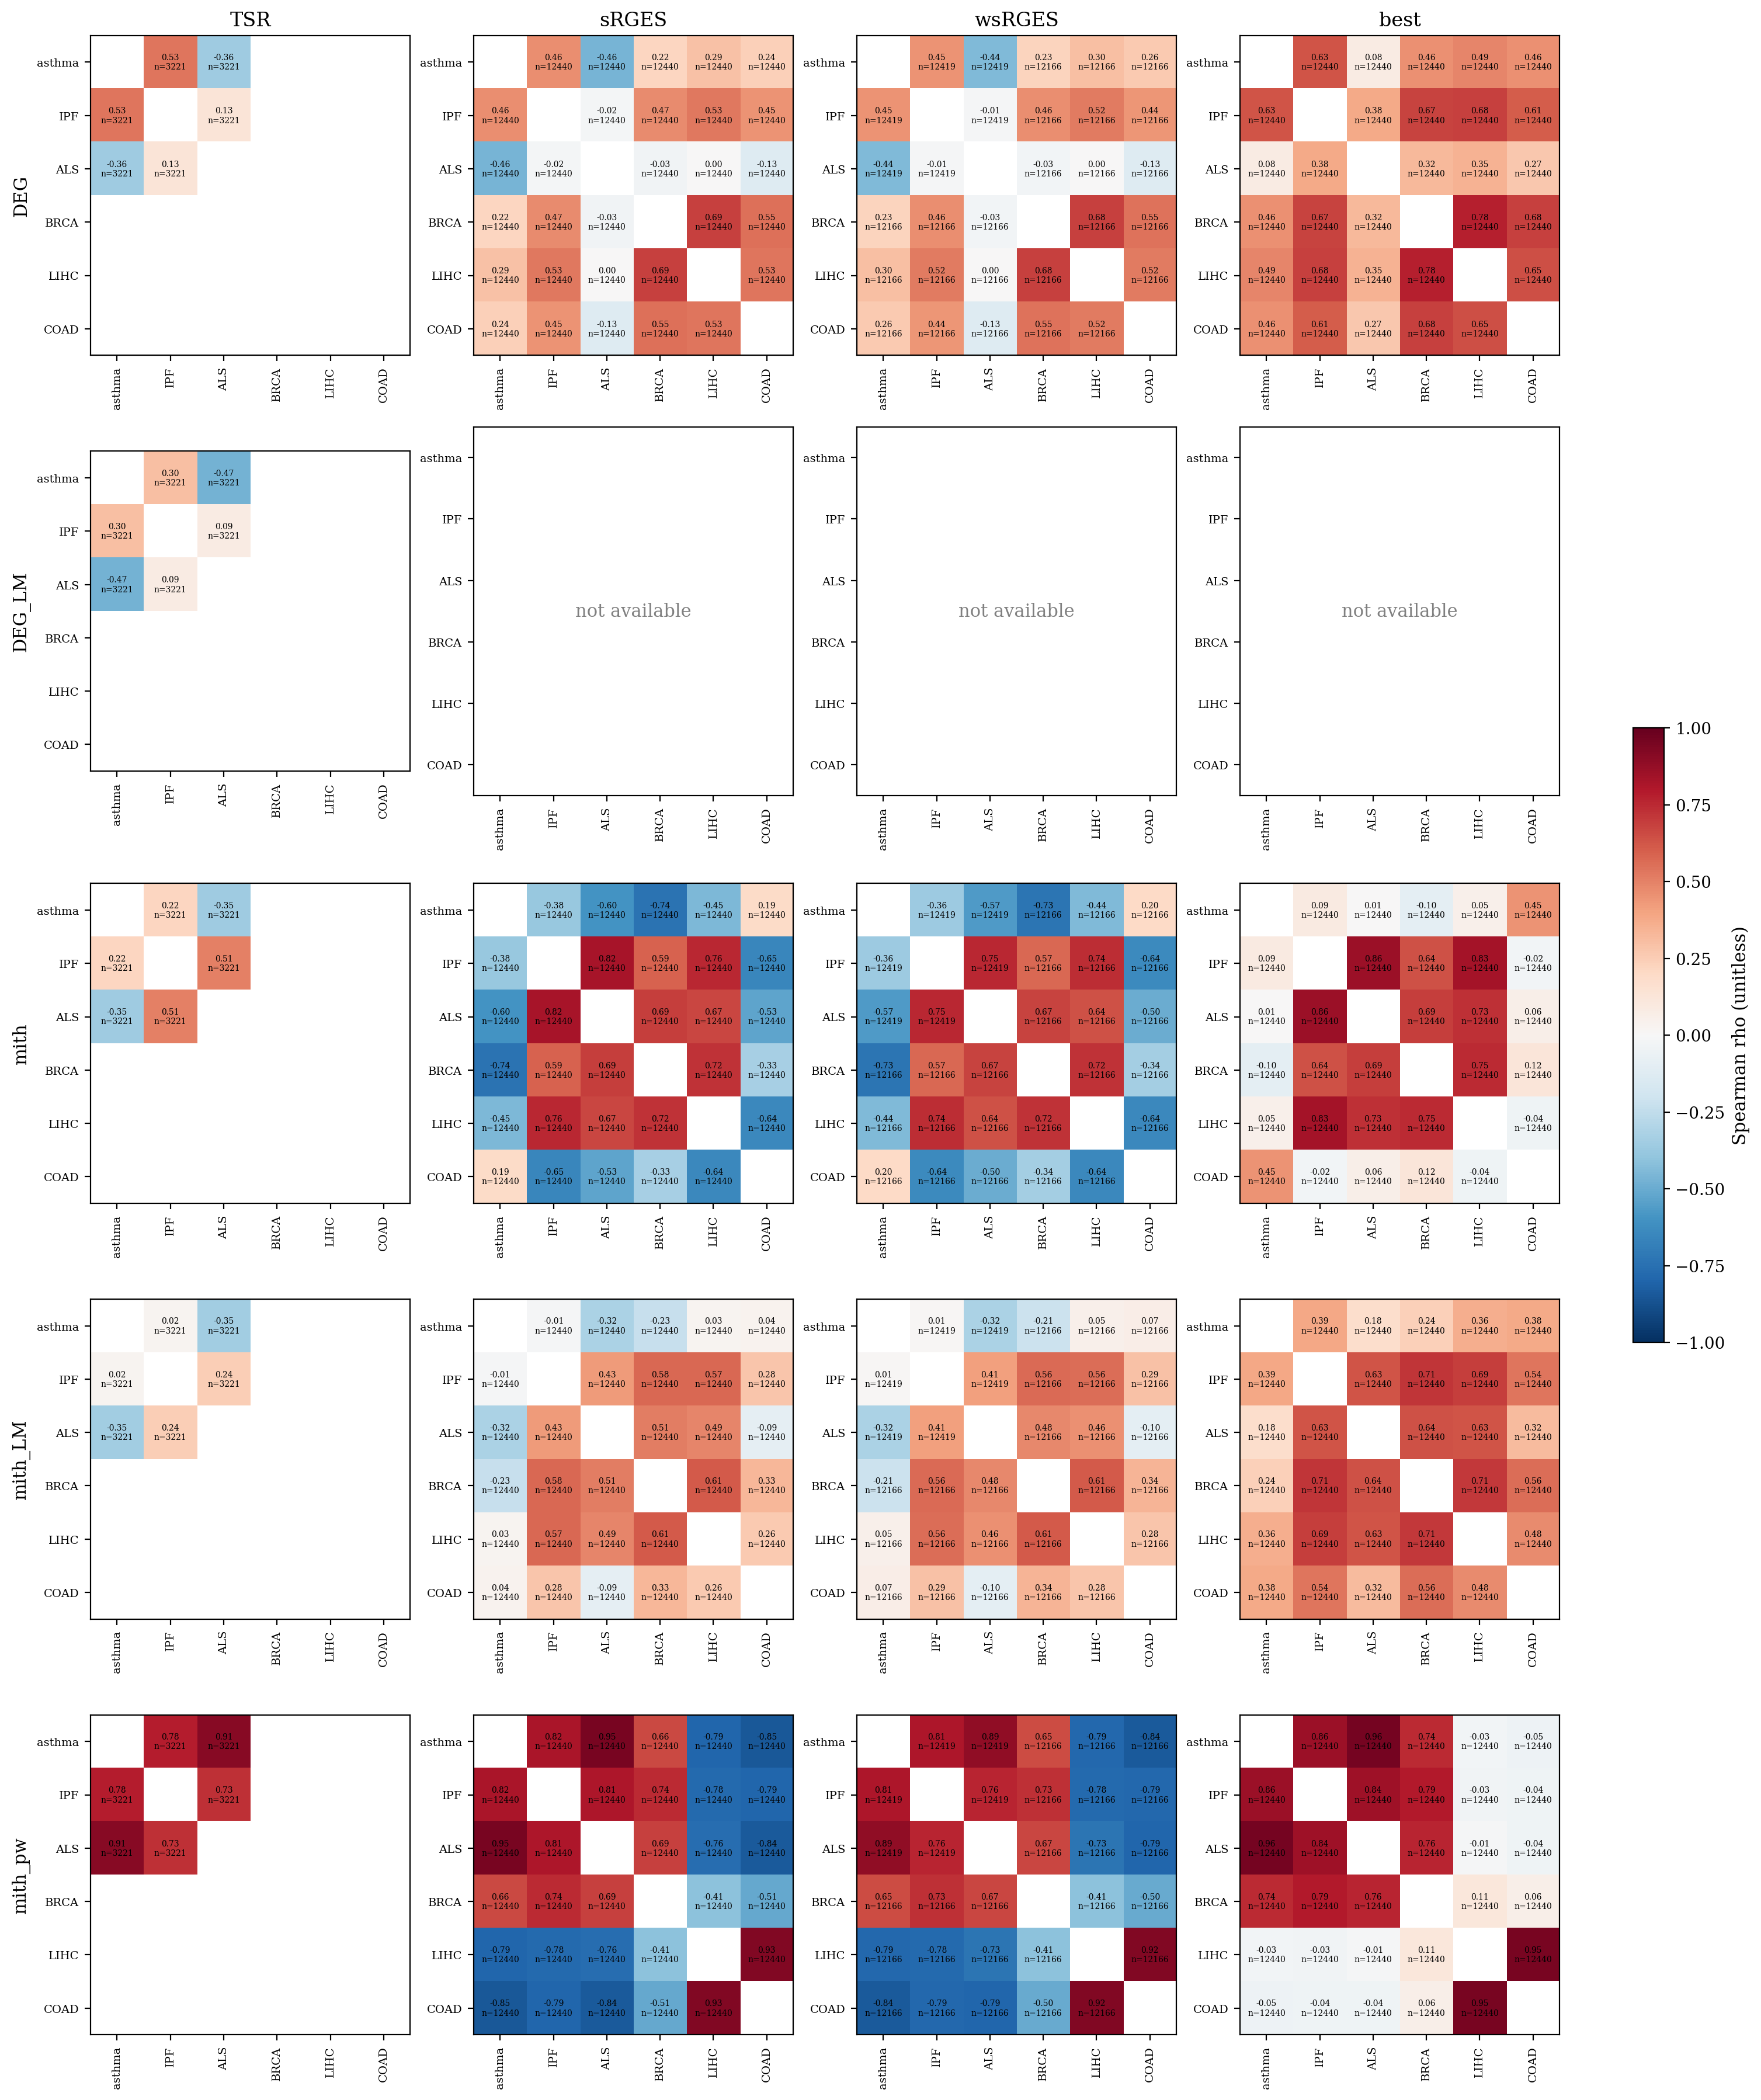

![Figure 1](../../../imgs/case_studies/cross_disease/cross_disease_supp_spearman_grid.png)

**Figure 1.** Spearman rho of the CS on shared drugs for every model: rows = representation (configuration), columns = collapse (score type); each panel is a disease x disease matrix. Shared diverging scale centred at 0 (red positive, blue negative); values annotated; unfiltered drugs. Each cell shows the value and n = number of shared drugs (count of compounds); hatched cells have fewer than 100 shared drugs.

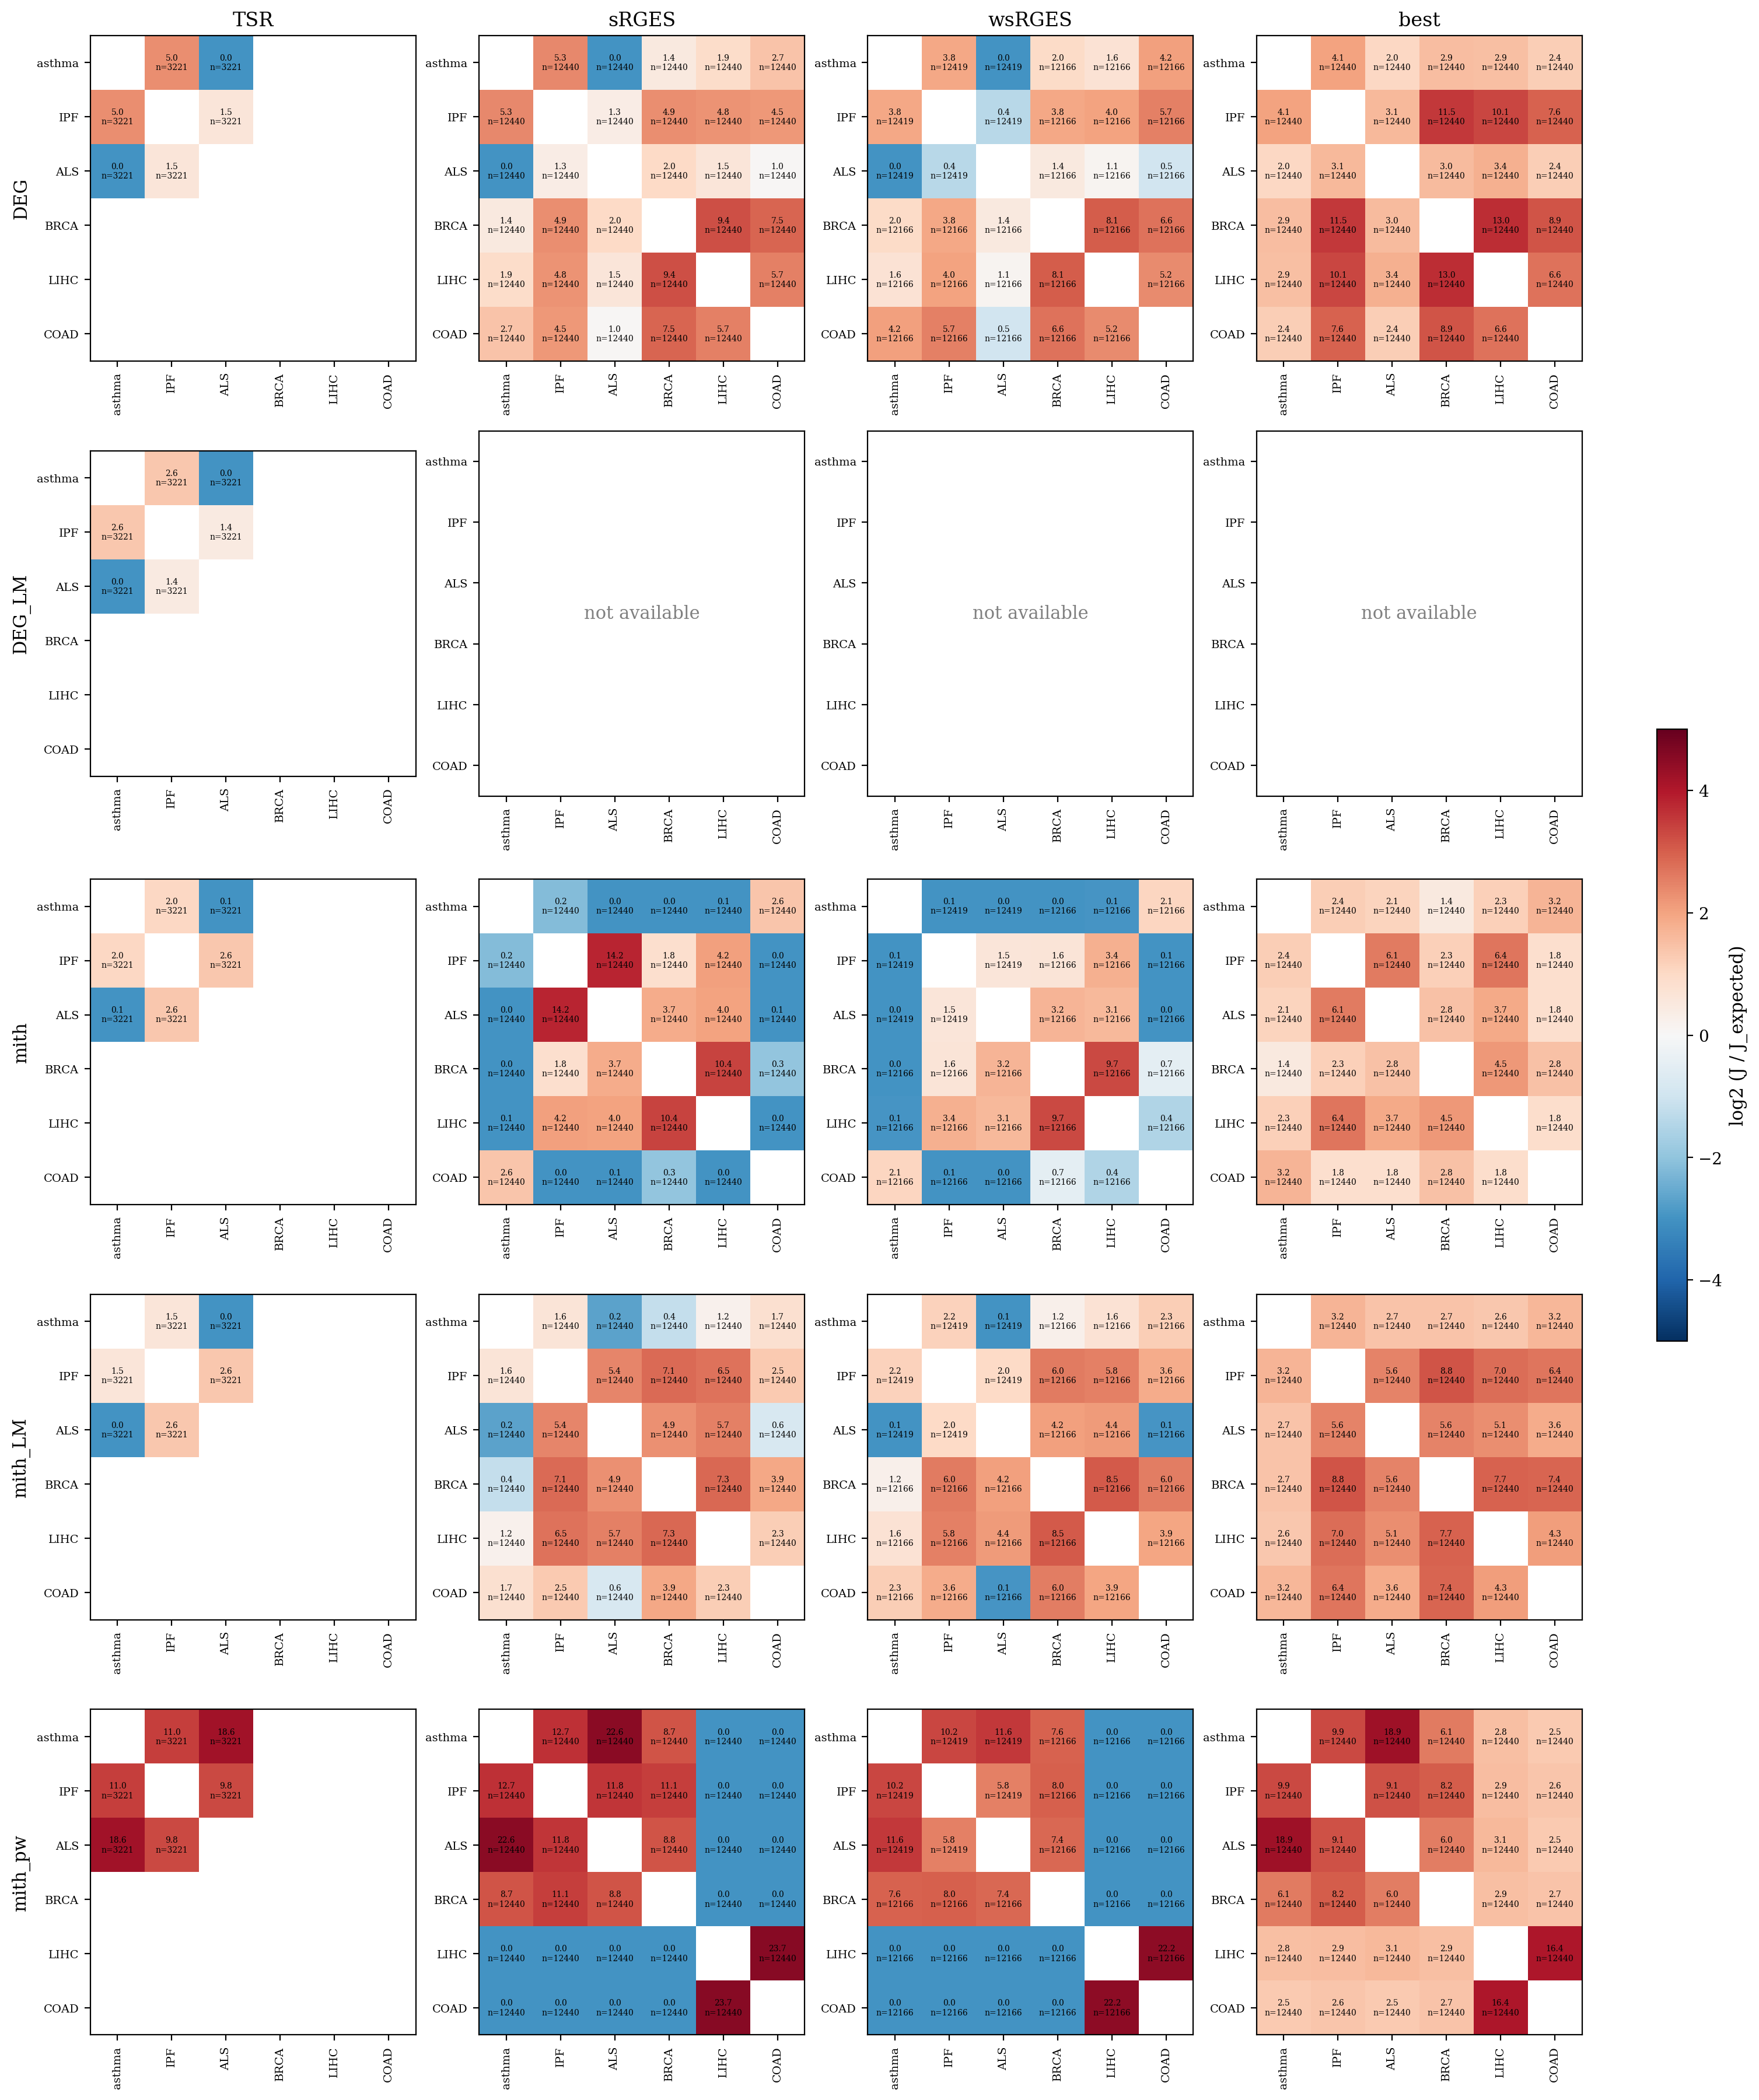

![Figure 2](../../../imgs/case_studies/cross_disease/cross_disease_supp_jaccard_grid.png)

**Figure 2.** Jaccard index of the top 5% sets divided by its hypergeometric null (J / J_expected, annotated) for every model; colour = log2 of that ratio, diverging scale centred at 0 (= overlap expected by chance); rows = representation, columns = collapse; unfiltered drugs. Each cell shows the value and n = number of shared drugs (count of compounds); hatched cells have fewer than 100 shared drugs.

In [8]:
# supplementary figure: representation (rows) x collapse (columns), disease x disease heatmaps
CFG_ROWS = ['DEG', 'DEG_LM', 'mith', 'mith_LM', 'mith_pw']; COL_COLS = ['TSR', 'sRGES', 'wsRGES', 'best']
def grid_fig(df, valcol, vmin, vmax, cmap, fmt, label, fname, caption):
    fig, axs = plt.subplots(len(CFG_ROWS), len(COL_COLS), figsize=(15, 18), constrained_layout=True)
    for i, c in enumerate(CFG_ROWS):
        for j, st in enumerate(COL_COLS):
            ax = axs[i, j]; ax.grid(False)
            d = df[(df['config'] == c) & (df['score_type'] == st)]
            ax.set_xticks(range(len(ds_all))); ax.set_yticks(range(len(ds_all)))
            ax.set_xticklabels(ds_all, rotation=90, fontsize=7); ax.set_yticklabels(ds_all, fontsize=7)
            if d.empty:
                ax.text(0.5, 0.5, 'not available', transform=ax.transAxes, ha='center', va='center', color='0.5'); ax.set_xlim(-.5, len(ds_all) - .5); ax.set_ylim(len(ds_all) - .5, -.5)
            else:
                Q = to_square(d, valcol).values
                im = ax.imshow(Q, vmin=vmin, vmax=vmax, cmap=cmap)
                Nn = to_square(d, 'n_shared').values
                for a in range(len(ds_all)):
                    for b in range(len(ds_all)):
                        if a != b and not np.isnan(Q[a, b]):
                            ax.text(b, a, f'{fmt(d_val(Q[a, b]))}\nn={int(Nn[a, b])}', ha='center', va='center', fontsize=5)
                            if Nn[a, b] < N_MARK: ax.add_patch(plt.Rectangle((b - .5, a - .5), 1, 1, fill=False, hatch='///', edgecolor='0.45', lw=0))
            if i == 0: ax.set_title(st)
            if j == 0: ax.set_ylabel(c, fontsize=11)
    fig.colorbar(im, ax=axs, shrink=0.3, label=label, location='right')
    show_fig(fig, fname, caption)

d_val = lambda v: v
grid_fig(S1, 'spearman', -1, 1, 'RdBu_r', lambda v: f'{v:.2f}', 'Spearman rho (unitless)', 'supp_spearman_grid',
         'Spearman rho of the CS on shared drugs for every model: rows = representation (configuration), columns = collapse (score type); each panel is a disease x disease matrix. Shared diverging scale centred at 0 (red positive, blue negative); values annotated; unfiltered drugs. Each cell shows the value and n = number of shared drugs (count of compounds); hatched cells have fewer than ' + str(N_MARK) + ' shared drugs.')
J1['log2ratio'] = np.log2(J1['ratio'].clip(lower=2 ** -3))
lim = float(np.ceil(J1['log2ratio'].abs().max()))
d_val = lambda v: v
Jg = J1.assign(valtxt=J1['ratio'])
# annotate J / J_expected, colour = log2(J / J_expected) (centred at 0 = chance)
def grid_fig_j():
    fig, axs = plt.subplots(len(CFG_ROWS), len(COL_COLS), figsize=(15, 18), constrained_layout=True)
    for i, c in enumerate(CFG_ROWS):
        for j, st in enumerate(COL_COLS):
            ax = axs[i, j]; ax.grid(False)
            d = J1[(J1['config'] == c) & (J1['score_type'] == st)]
            ax.set_xticks(range(len(ds_all))); ax.set_yticks(range(len(ds_all)))
            ax.set_xticklabels(ds_all, rotation=90, fontsize=7); ax.set_yticklabels(ds_all, fontsize=7)
            if d.empty:
                ax.text(0.5, 0.5, 'not available', transform=ax.transAxes, ha='center', va='center', color='0.5'); ax.set_xlim(-.5, len(ds_all) - .5); ax.set_ylim(len(ds_all) - .5, -.5)
            else:
                Q = to_square(d, 'log2ratio').values; Rr = to_square(d, 'ratio').values; Jj = to_square(d, 'jaccard').values; Nn = to_square(d, 'n_shared').values
                im = ax.imshow(Q, vmin=-lim, vmax=lim, cmap='RdBu_r')
                for a in range(len(ds_all)):
                    for b in range(len(ds_all)):
                        if a != b and not np.isnan(Rr[a, b]):
                            ax.text(b, a, f'{Rr[a, b]:.1f}\nn={int(Nn[a, b])}', ha='center', va='center', fontsize=5)
                            if Nn[a, b] < N_MARK: ax.add_patch(plt.Rectangle((b - .5, a - .5), 1, 1, fill=False, hatch='///', edgecolor='0.45', lw=0))
            if i == 0: ax.set_title(st)
            if j == 0: ax.set_ylabel(c, fontsize=11)
    fig.colorbar(im, ax=axs, shrink=0.3, label='log2 (J / J_expected)', location='right')
    show_fig(fig, 'supp_jaccard_grid', f'Jaccard index of the top {JAC_K.replace("pct", "%")} sets divided by its hypergeometric null (J / J_expected, annotated) for every model; colour = log2 of that ratio, diverging scale centred at 0 (= overlap expected by chance); rows = representation, columns = collapse; unfiltered drugs. Each cell shows the value and n = number of shared drugs (count of compounds); hatched cells have fewer than ' + str(N_MARK) + ' shared drugs.')
grid_fig_j()

### 2.2 Dot plot: one dot per model

For each disease pair, one dot per per-instance model: Spearman rho (left) and J / J_expected on a log scale (right; a ratio of 0 is off the axis). Colour = model family (DEG family: `DEG`; MITHrIL family: `mith`, `mith_LM`, `mith_pw`); diamonds = `mith_pw`; open squares = TSR models (shown for the non-cancer pairs, not averaged in); the black tick is the Fisher-z mean of rho (left) and the median ratio (right).

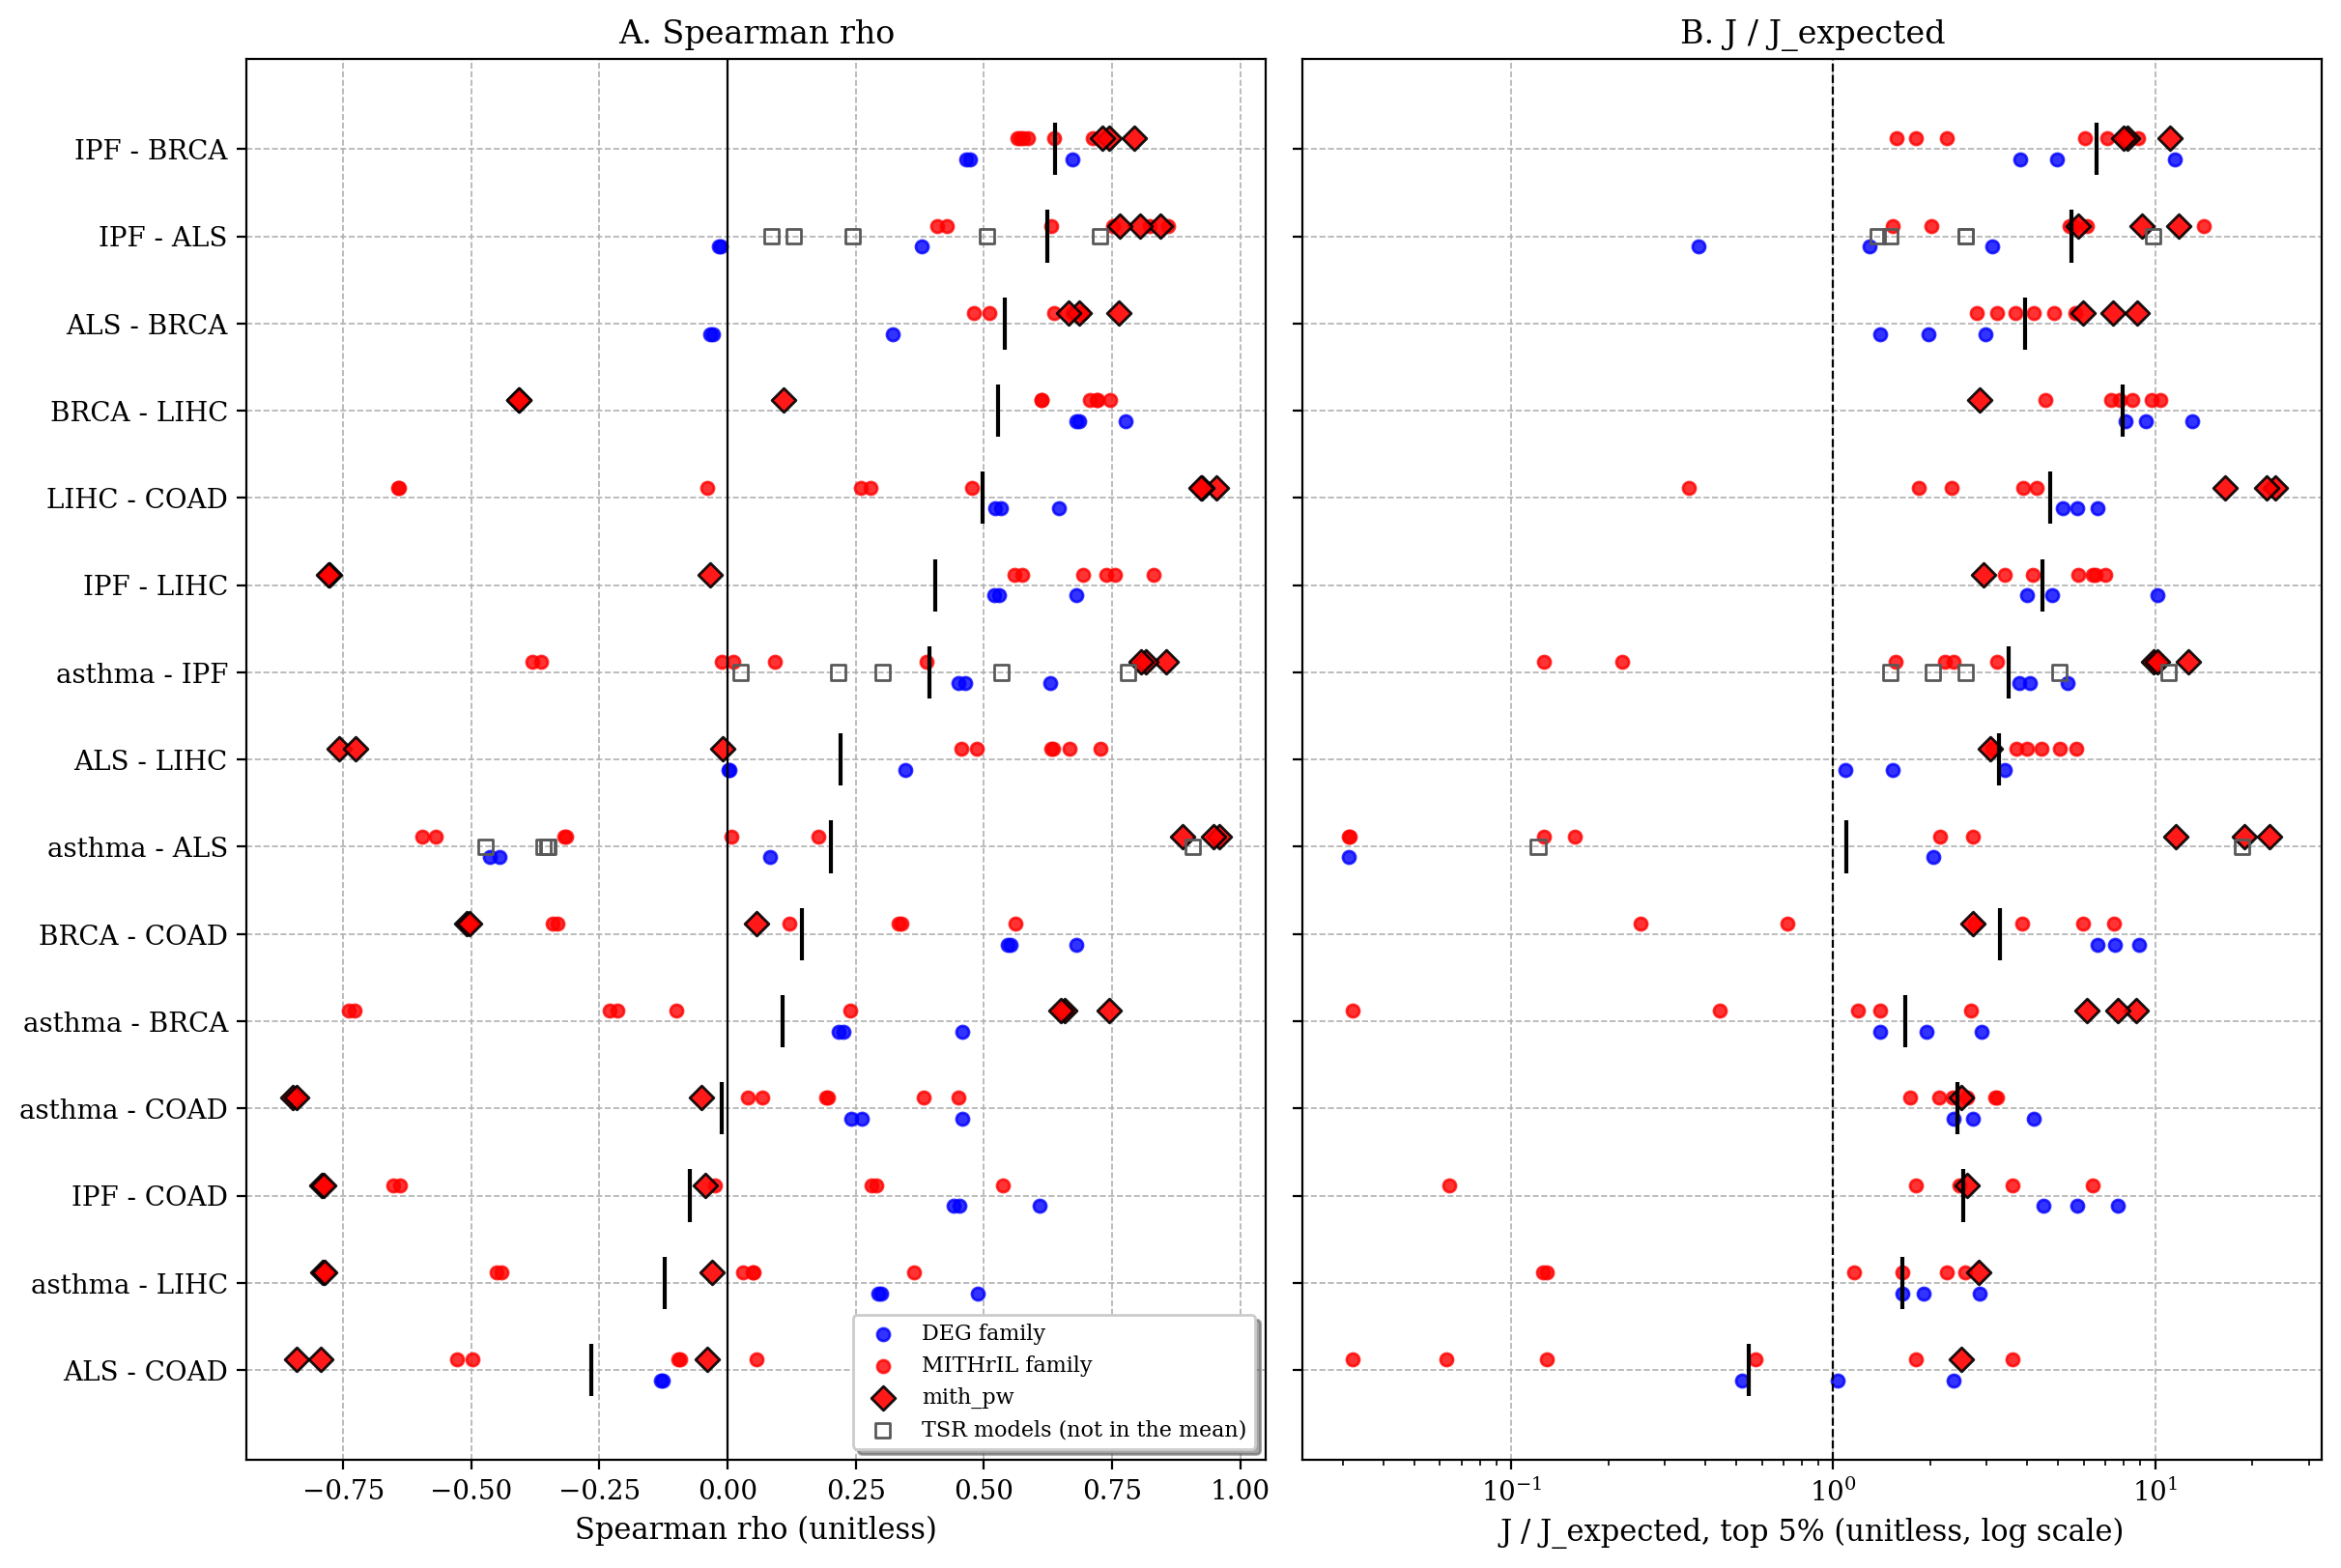

![Figure 3](../../../imgs/case_studies/cross_disease/cross_disease_dotplot_pairs.png)

**Figure 3.** Agreement of drug rankings per disease pair, one dot per per-instance model (12 models). Blue = DEG (the only DEG-family per-instance configuration), red = MITHrIL family, diamonds = mith_pw, open squares = TSR models (non-cancer pairs only; not in the black tick), black tick = across per-instance-model summary (Fisher-z mean for rho, median for J / J_expected); pairs sorted by mean rho. B: dashed line = overlap expected by chance. Unfiltered drugs.

In [9]:
pair_lab = {p: f'{p[0]} - {p[1]}' for p in pairs}
order_pairs = sorted(pairs, key=lambda p: CP.set_index(['disease_a', 'disease_b']).loc[p, 'rho_fisher_mean'])
fig, axs = plt.subplots(1, 2, figsize=(12, 8), constrained_layout=True, sharey=True)
for ax, (df, col, xl) in zip(axs, [(S1p, 'spearman', 'Spearman rho (unitless)'), (J1p, 'ratio', f'J / J_expected, top {JAC_K.replace("pct", "%")} (unitless, log scale)')]):
    for yi, p in enumerate(order_pairs):
        d = df[(df['disease_a'] == p[0]) & (df['disease_b'] == p[1])]
        for fam, c in FAM_COL.items():
            v = d[(d['family_name'] == fam) & (d['config'] != 'mith_pw')]; w = d[d['config'] == 'mith_pw']
            off = -0.12 if fam == 'DEG family' else 0.12
            ax.scatter(v[col], np.full(len(v), yi) + off, s=22, color=c, alpha=0.8, label=fam if yi == 0 else None)
            if fam == 'MITHrIL family': ax.scatter(w[col], np.full(len(w), yi) + off, s=40, color=c, marker='D', edgecolor='k', alpha=0.9, label='mith_pw' if yi == 0 else None)
        dt = (S1t if col == 'spearman' else J1t); dt = dt[(dt['disease_a'] == p[0]) & (dt['disease_b'] == p[1])]
        ax.scatter(dt[col], np.full(len(dt), yi), s=30, facecolor='none', edgecolor='0.35', marker='s', label='TSR models (not in the mean)' if (yi == 0 and col == 'spearman') else None)
        m = CP.set_index(['disease_a', 'disease_b']).loc[p, 'rho_fisher_mean' if col == 'spearman' else 'ratio_median']
        ax.vlines(m, yi - 0.3, yi + 0.3, color='k')
    ax.set_yticks(range(len(order_pairs))); ax.set_yticklabels([pair_lab[p] for p in order_pairs]); ax.set_xlabel(xl)
    if col == 'spearman': ax.axvline(0, color='k', lw=0.8)
    else: ax.set_xscale('log'); ax.axvline(1, color='k', lw=0.8, ls='--')
axs[0].legend(fontsize=8, loc='lower right'); axs[0].set_title('A. Spearman rho'); axs[1].set_title('B. J / J_expected')
show_fig(fig, 'dotplot_pairs', 'Agreement of drug rankings per disease pair, one dot per per-instance model (12 models). Blue = DEG (the only DEG-family per-instance configuration), red = MITHrIL family, diamonds = mith_pw, open squares = TSR models (non-cancer pairs only; not in the black tick), black tick = across per-instance-model summary (Fisher-z mean for rho, median for J / J_expected); pairs sorted by mean rho. B: dashed line = overlap expected by chance. Unfiltered drugs.')

### 2.3 Model families

DEG family vs MITHrIL family (`mith`, `mith_LM`, `mith_pw`), and `mith_pw` on its own, on the per-instance models only. The per-instance runs contain no `DEG_LM` model, so the DEG family is `DEG` alone (3 models: sRGES, wsRGES, best) against 9 MITHrIL models (3 per configuration). Per family: Fisher-z mean rho and median J / J_expected over its models. The family difference
(MITHrIL minus DEG) carries a 95% bootstrap interval per disease pair: `N_BOOT` resamples (seed 0) of the drugs with replacement, the same resample used for every model of a pair; each model's rho (Pearson correlation of the ranks of the shared drugs,
with multiplicity weights) and J / J_expected (top 5% of the distinct resampled drugs) is recomputed, then summarised by family. Intervals are the 2.5 and 97.5 percentiles. The resampling is over drugs only: the models are fixed, so the intervals describe the stability of the difference under drug resampling, not variation across models.

In [10]:
from scipy.stats import rankdata
rng = np.random.default_rng(SEED)
key_index = {k: i for i, k in enumerate(sorted(set(R['drug_key'])))}
nU = len(key_index)
FAMS = {'DEG family': ['DEG'], 'MITHrIL family': ['mith', 'mith_LM', 'mith_pw'], 'mith_pw': ['mith_pw']}
model_cfg = sl.set_index('model')['config'].to_dict()
piv = {}
for slc, g in R.groupby('model', observed=True):
    p = g.pivot(index='drug_key', columns='disease', values='score')
    piv[slc] = p
fam_of = sl.set_index('model')['family'].to_dict()
models_by_pair = {p: [s for s, pv in piv.items() if fam_of.get(s) == 'per-instance' and p[0] in pv.columns and p[1] in pv.columns and (pv[p[0]].notna() & pv[p[1]].notna()).any()] for p in pairs}

def boot_pair(p):
    mods = []
    for s in models_by_pair[p]:
        pv = piv[s]; m = pv[p[0]].notna() & pv[p[1]].notna()
        x, y = pv.loc[m, p[0]], pv.loc[m, p[1]]
        mods.append(dict(model=s, cfg=model_cfg[s], pos=np.array([key_index[k] for k in x.index]), rx=rankdata(x.values), ry=rankdata(y.values)))
    B = N_BOOT
    rho = np.full((B, len(mods)), np.nan); ratio = np.full((B, len(mods)), np.nan)
    for b in range(B):
        counts = np.bincount(rng.integers(0, nU, nU), minlength=nU)
        for mi, m in enumerate(mods):
            w = counts[m['pos']].astype(float); n = w.sum()
            mx = (w * m['rx']).sum() / n; my = (w * m['ry']).sum() / n
            cov = (w * (m['rx'] - mx) * (m['ry'] - my)).sum()
            den = np.sqrt((w * (m['rx'] - mx) ** 2).sum() * (w * (m['ry'] - my) ** 2).sum())
            rho[b, mi] = cov / den
            inc = w > 0; nn = int(inc.sum()); k = max(2, int(round(TOP_FRAC * nn)))
            if k < nn:
                a = m['rx'][inc]; c = m['ry'][inc]
                ov = int(((a <= np.partition(a, k - 1)[k - 1]) & (c <= np.partition(c, k - 1)[k - 1])).sum())
                ratio[b, mi] = (ov / (2 * k - ov)) / jaccard_null(nn, k)
    return mods, rho, ratio

fam_rows, diff_rows = [], []
for p in pairs:
    mods, rho, ratio = boot_pair(p)
    cfgs = np.array([m['cfg'] for m in mods])
    est = {}
    for fam, cl in FAMS.items():
        idx = [i for i, c in enumerate(cfgs) if c in cl]
        if not idx: continue
        zb = np.tanh(np.arctanh(np.clip(rho[:, idx], -0.999999, 0.999999)).mean(axis=1)); rb = np.nanmedian(ratio[:, idx], axis=1)
        s1 = S1p[(S1p['disease_a'] == p[0]) & (S1p['disease_b'] == p[1]) & (S1p['config'].isin(cl))]; j1 = J1p[(J1p['disease_a'] == p[0]) & (J1p['disease_b'] == p[1]) & (J1p['config'].isin(cl))]
        est[fam] = (fisher_mean(s1['spearman'].values), j1['ratio'].median(), zb, rb)
        fam_rows.append({'disease_a': p[0], 'disease_b': p[1], 'family': fam, 'n_models': len(idx), 'rho_fisher_mean': est[fam][0], 'ratio_median': est[fam][1]})
    if 'DEG family' in est and 'MITHrIL family' in est:
        e1, e2 = est['MITHrIL family'], est['DEG family']
        dz = np.arctanh(e1[2].clip(-0.999999, 0.999999)) - np.arctanh(e2[2].clip(-0.999999, 0.999999))
        diff_rows.append({'disease_a': p[0], 'disease_b': p[1], 'rho_diff_z': np.arctanh(e1[0]) - np.arctanh(e2[0]), 'rho_diff_z_lo': np.percentile(dz, 2.5), 'rho_diff_z_hi': np.percentile(dz, 97.5),
                          'ratio_diff': e1[1] - e2[1], 'ratio_diff_lo': np.nanpercentile(e1[3] - e2[3], 2.5), 'ratio_diff_hi': np.nanpercentile(e1[3] - e2[3], 97.5),
                          'rho_diff': e1[0] - e2[0], 'rho_diff_lo': np.percentile(e1[2] - e2[2], 2.5), 'rho_diff_hi': np.percentile(e1[2] - e2[2], 97.5)})
FR = pd.DataFrame(fam_rows); DR = pd.DataFrame(diff_rows)
save(FR, 'family_collapse'); save(DR, 'family_difference_bootstrap')
for fam in FAMS:
    f = FR[FR['family'] == fam]
    if f.empty: continue
    nm = int(f['n_models'].iloc[0]); nshp = f"shared drugs per pair {NSH_PI}"
    show_table(to_square(f, 'rho_fisher_mean'), f'{fam} ({", ".join(FAMS[fam])}; {nm} per-instance models): Fisher-z mean Spearman rho (unitless) per disease pair; {nshp}.', fmt='{:.2f}', index=True)
    show_table(to_square(f, 'ratio_median'), f'{fam} ({nm} per-instance models): median J / J_expected (top {JAC_K.replace("pct", "%")}; unitless) per disease pair; {nshp}.', fmt='{:.1f}', index=True)
DRt = DR.assign(pair=DR['disease_a'] + ' - ' + DR['disease_b'], pair_class=[pair_class(a, b) for a, b in zip(DR['disease_a'], DR['disease_b'])])
t = DRt[['pair', 'pair_class', 'rho_diff', 'rho_diff_lo', 'rho_diff_hi', 'ratio_diff', 'ratio_diff_lo', 'ratio_diff_hi']]
show_table(t, f'Difference MITHrIL family minus DEG family per disease pair: in Fisher-z-mean rho (unitless; difference of the family rhos) and in median J / J_expected (unitless), each with a 95% bootstrap interval (lo, hi) over {N_BOOT} resamples of the shared drugs (seed {SEED}); 3 DEG models vs 9 MITHrIL models, per-instance only. The resampling is over drugs only, so an interval excluding 0 means that the difference is stable under drug resampling; it does not test variation across models or configurations (the models of a family are correlated and differ in composition).', fmt='{:.2f}')
sq = lambda c: to_square(DR, c)
show_table(sq('rho_diff'), 'Difference MITHrIL family minus DEG family in Fisher-z-mean Spearman rho (unitless), per disease pair.', fmt='{:.2f}', index=True)

**Table 16.** DEG family (DEG; 3 per-instance models): Fisher-z mean Spearman rho (unitless) per disease pair; shared drugs per pair 12166-12440.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 0.52 | -0.29 | 0.30 | 0.36 | 0.32 |
| IPF | 0.52 |  | 0.12 | 0.54 | 0.58 | 0.50 |
| ALS | -0.29 | 0.12 |  | 0.09 | 0.12 | 0.00 |
| BRCA | 0.30 | 0.54 | 0.09 |  | 0.72 | 0.60 |
| LIHC | 0.36 | 0.58 | 0.12 | 0.72 |  | 0.57 |
| COAD | 0.32 | 0.50 | 0.00 | 0.60 | 0.57 |  |

**Table 17.** DEG family (3 per-instance models): median J / J_expected (top 5%; unitless) per disease pair; shared drugs per pair 12166-12440.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 4.1 | 0.0 | 2.0 | 1.9 | 2.7 |
| IPF | 4.1 |  | 1.3 | 4.9 | 4.8 | 5.7 |
| ALS | 0.0 | 1.3 |  | 2.0 | 1.5 | 1.0 |
| BRCA | 2.0 | 4.9 | 2.0 |  | 9.4 | 7.5 |
| LIHC | 1.9 | 4.8 | 1.5 | 9.4 |  | 5.7 |
| COAD | 2.7 | 5.7 | 1.0 | 7.5 | 5.7 |  |

**Table 18.** MITHrIL family (mith, mith_LM, mith_pw; 9 per-instance models): Fisher-z mean Spearman rho (unitless) per disease pair; shared drugs per pair 12166-12440.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 0.35 | 0.36 | 0.04 | -0.28 | -0.13 |
| IPF | 0.35 |  | 0.73 | 0.67 | 0.34 | -0.28 |
| ALS | 0.36 | 0.73 |  | 0.65 | 0.25 | -0.35 |
| BRCA | 0.04 | 0.67 | 0.65 |  | 0.45 | -0.03 |
| LIHC | -0.28 | 0.34 | 0.25 | 0.45 |  | 0.47 |
| COAD | -0.13 | -0.28 | -0.35 | -0.03 | 0.47 |  |

**Table 19.** MITHrIL family (9 per-instance models): median J / J_expected (top 5%; unitless) per disease pair; shared drugs per pair 12166-12440.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 2.4 | 2.1 | 1.4 | 1.2 | 2.3 |
| IPF | 2.4 |  | 5.8 | 7.1 | 4.2 | 1.8 |
| ALS | 2.1 | 5.8 |  | 4.9 | 3.7 | 0.1 |
| BRCA | 1.4 | 7.1 | 4.9 |  | 7.3 | 2.7 |
| LIHC | 1.2 | 4.2 | 3.7 | 7.3 |  | 3.9 |
| COAD | 2.3 | 1.8 | 0.1 | 2.7 | 3.9 |  |

**Table 20.** mith_pw (mith_pw; 3 per-instance models): Fisher-z mean Spearman rho (unitless) per disease pair; shared drugs per pair 12166-12440.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 0.83 | 0.94 | 0.69 | -0.62 | -0.69 |
| IPF | 0.83 |  | 0.81 | 0.76 | -0.61 | -0.62 |
| ALS | 0.94 | 0.81 |  | 0.71 | -0.57 | -0.65 |
| BRCA | 0.69 | 0.76 | 0.71 |  | -0.25 | -0.34 |
| LIHC | -0.62 | -0.61 | -0.57 | -0.25 |  | 0.94 |
| COAD | -0.69 | -0.62 | -0.65 | -0.34 | 0.94 |  |

**Table 21.** mith_pw (3 per-instance models): median J / J_expected (top 5%; unitless) per disease pair; shared drugs per pair 12166-12440.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | 10.2 | 18.9 | 7.6 | 0.0 | 0.0 |
| IPF | 10.2 |  | 9.1 | 8.2 | 0.0 | 0.0 |
| ALS | 18.9 | 9.1 |  | 7.4 | 0.0 | 0.0 |
| BRCA | 7.6 | 8.2 | 7.4 |  | 0.0 | 0.0 |
| LIHC | 0.0 | 0.0 | 0.0 | 0.0 |  | 22.2 |
| COAD | 0.0 | 0.0 | 0.0 | 0.0 | 22.2 |  |

**Table 22.** Difference MITHrIL family minus DEG family per disease pair: in Fisher-z-mean rho (unitless; difference of the family rhos) and in median J / J_expected (unitless), each with a 95% bootstrap interval (lo, hi) over 1000 resamples of the shared drugs (seed 0); 3 DEG models vs 9 MITHrIL models, per-instance only. The resampling is over drugs only, so an interval excluding 0 means that the difference is stable under drug resampling; it does not test variation across models or configurations (the models of a family are correlated and differ in composition).

| pair | pair_class | rho_diff | rho_diff_lo | rho_diff_hi | ratio_diff | ratio_diff_lo | ratio_diff_hi |
|---|---|---|---|---|---|---|---|
| asthma - IPF | non-cancer | -0.17 | -0.19 | -0.16 | -1.73 | -2.28 | -1.16 |
| asthma - ALS | non-cancer | 0.65 | 0.63 | 0.66 | 2.12 | 1.70 | 2.48 |
| asthma - BRCA | cancer vs non-cancer | -0.27 | -0.28 | -0.25 | -0.56 | -1.02 | -0.09 |
| asthma - LIHC | cancer vs non-cancer | -0.65 | -0.66 | -0.63 | -0.74 | -1.19 | -0.32 |
| asthma - COAD | cancer vs non-cancer | -0.45 | -0.46 | -0.43 | -0.37 | -0.86 | 0.11 |
| IPF - ALS | non-cancer | 0.61 | 0.59 | 0.63 | 4.47 | 4.04 | 5.10 |
| IPF - BRCA | cancer vs non-cancer | 0.12 | 0.11 | 0.13 | 2.13 | 1.23 | 2.87 |
| IPF - LIHC | cancer vs non-cancer | -0.24 | -0.26 | -0.23 | -0.62 | -1.47 | 0.13 |
| IPF - COAD | cancer vs non-cancer | -0.78 | -0.80 | -0.77 | -3.94 | -4.70 | -3.23 |
| ALS - BRCA | cancer vs non-cancer | 0.56 | 0.54 | 0.58 | 2.89 | 2.26 | 3.44 |
| ALS - LIHC | cancer vs non-cancer | 0.13 | 0.12 | 0.15 | 2.17 | 1.58 | 2.64 |
| ALS - COAD | cancer vs non-cancer | -0.35 | -0.37 | -0.34 | -0.90 | -1.12 | -0.60 |
| BRCA - LIHC | cancer-cancer | -0.27 | -0.28 | -0.26 | -2.08 | -3.16 | -1.30 |
| BRCA - COAD | cancer-cancer | -0.63 | -0.64 | -0.62 | -4.80 | -5.70 | -4.19 |
| LIHC - COAD | cancer-cancer | -0.10 | -0.11 | -0.09 | -1.83 | -2.61 | -1.13 |

**Table 23.** Difference MITHrIL family minus DEG family in Fisher-z-mean Spearman rho (unitless), per disease pair.

| disease | asthma | IPF | ALS | BRCA | LIHC | COAD |
|---|---|---|---|---|---|---|
| asthma |  | -0.17 | 0.65 | -0.27 | -0.65 | -0.45 |
| IPF | -0.17 |  | 0.61 | 0.12 | -0.24 | -0.78 |
| ALS | 0.65 | 0.61 |  | 0.56 | 0.13 | -0.35 |
| BRCA | -0.27 | 0.12 | 0.56 |  | -0.27 | -0.63 |
| LIHC | -0.65 | -0.24 | 0.13 | -0.27 |  | -0.10 |
| COAD | -0.45 | -0.78 | -0.35 | -0.63 | -0.10 |  |

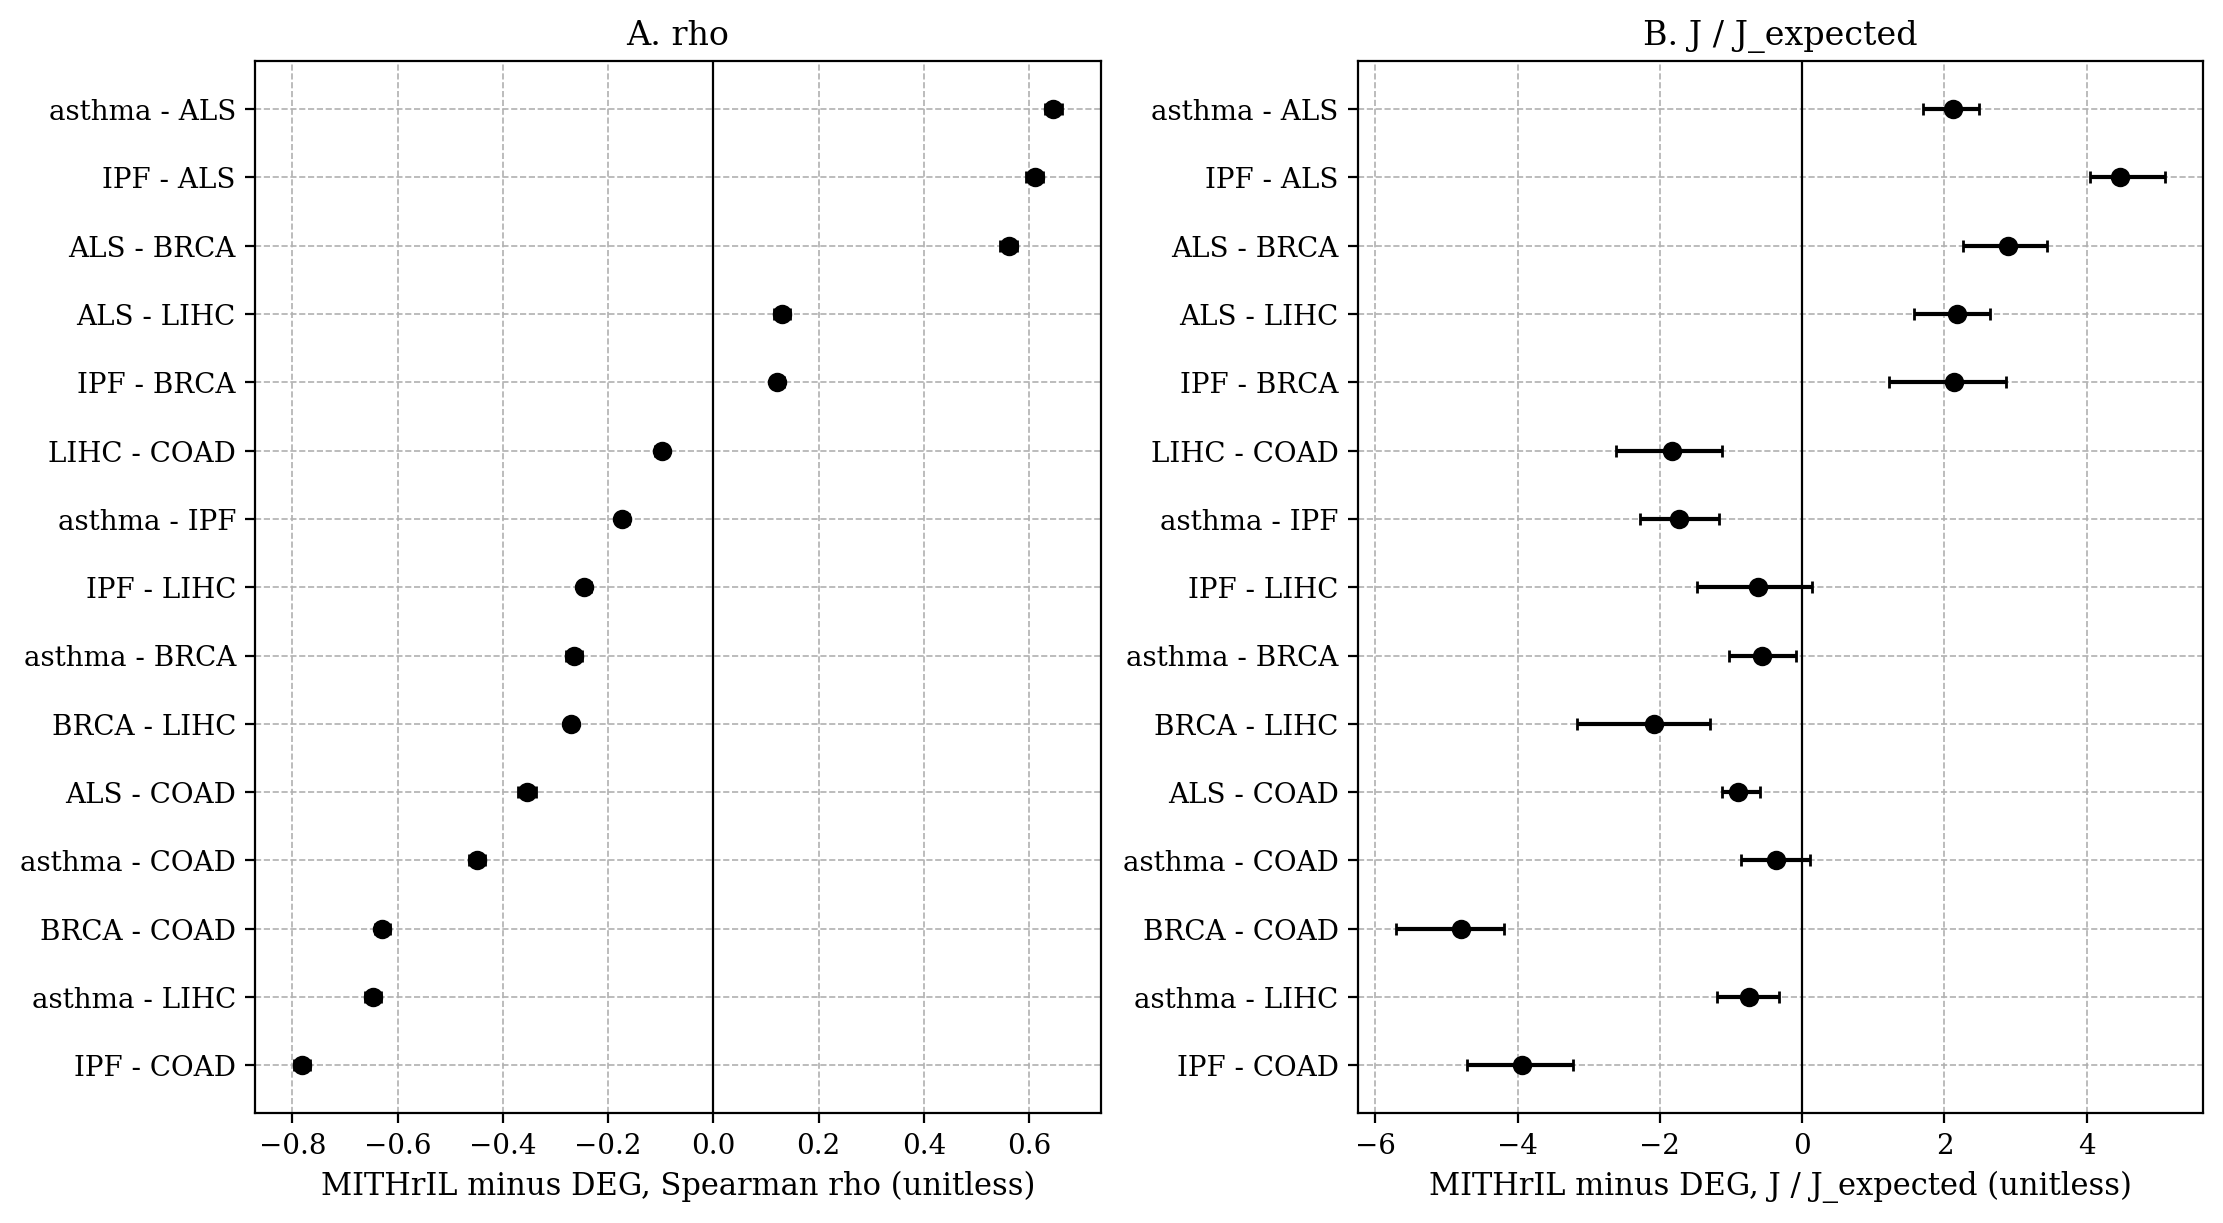

![Figure 4](../../../imgs/case_studies/cross_disease/cross_disease_family_difference.png)

**Figure 4.** Difference between the MITHrIL family and the DEG family per disease pair, with 95% bootstrap intervals over 1000 resamples of the shared drugs. Unfiltered drugs.

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(11, 6), constrained_layout=True)
Dp = DR.assign(pair=DR['disease_a'] + ' - ' + DR['disease_b']).sort_values('rho_diff')
for ax, (c, lo, hi, ttl, xl) in zip(axs, [('rho_diff', 'rho_diff_lo', 'rho_diff_hi', 'A. rho', 'MITHrIL minus DEG, Spearman rho (unitless)'),
                                         ('ratio_diff', 'ratio_diff_lo', 'ratio_diff_hi', f'B. J / J_expected', 'MITHrIL minus DEG, J / J_expected (unitless)')]):
    y = np.arange(len(Dp))
    ax.errorbar(Dp[c], y, xerr=[Dp[c] - Dp[lo], Dp[hi] - Dp[c]], fmt='o', color='k', capsize=2)
    ax.axvline(0, color='k', lw=0.8); ax.set_yticks(y); ax.set_yticklabels(Dp['pair']); ax.set_xlabel(xl); ax.set_title(ttl)
show_fig(fig, 'family_difference', f'Difference between the MITHrIL family and the DEG family per disease pair, with 95% bootstrap intervals over {N_BOOT} resamples of the shared drugs. Unfiltered drugs.')

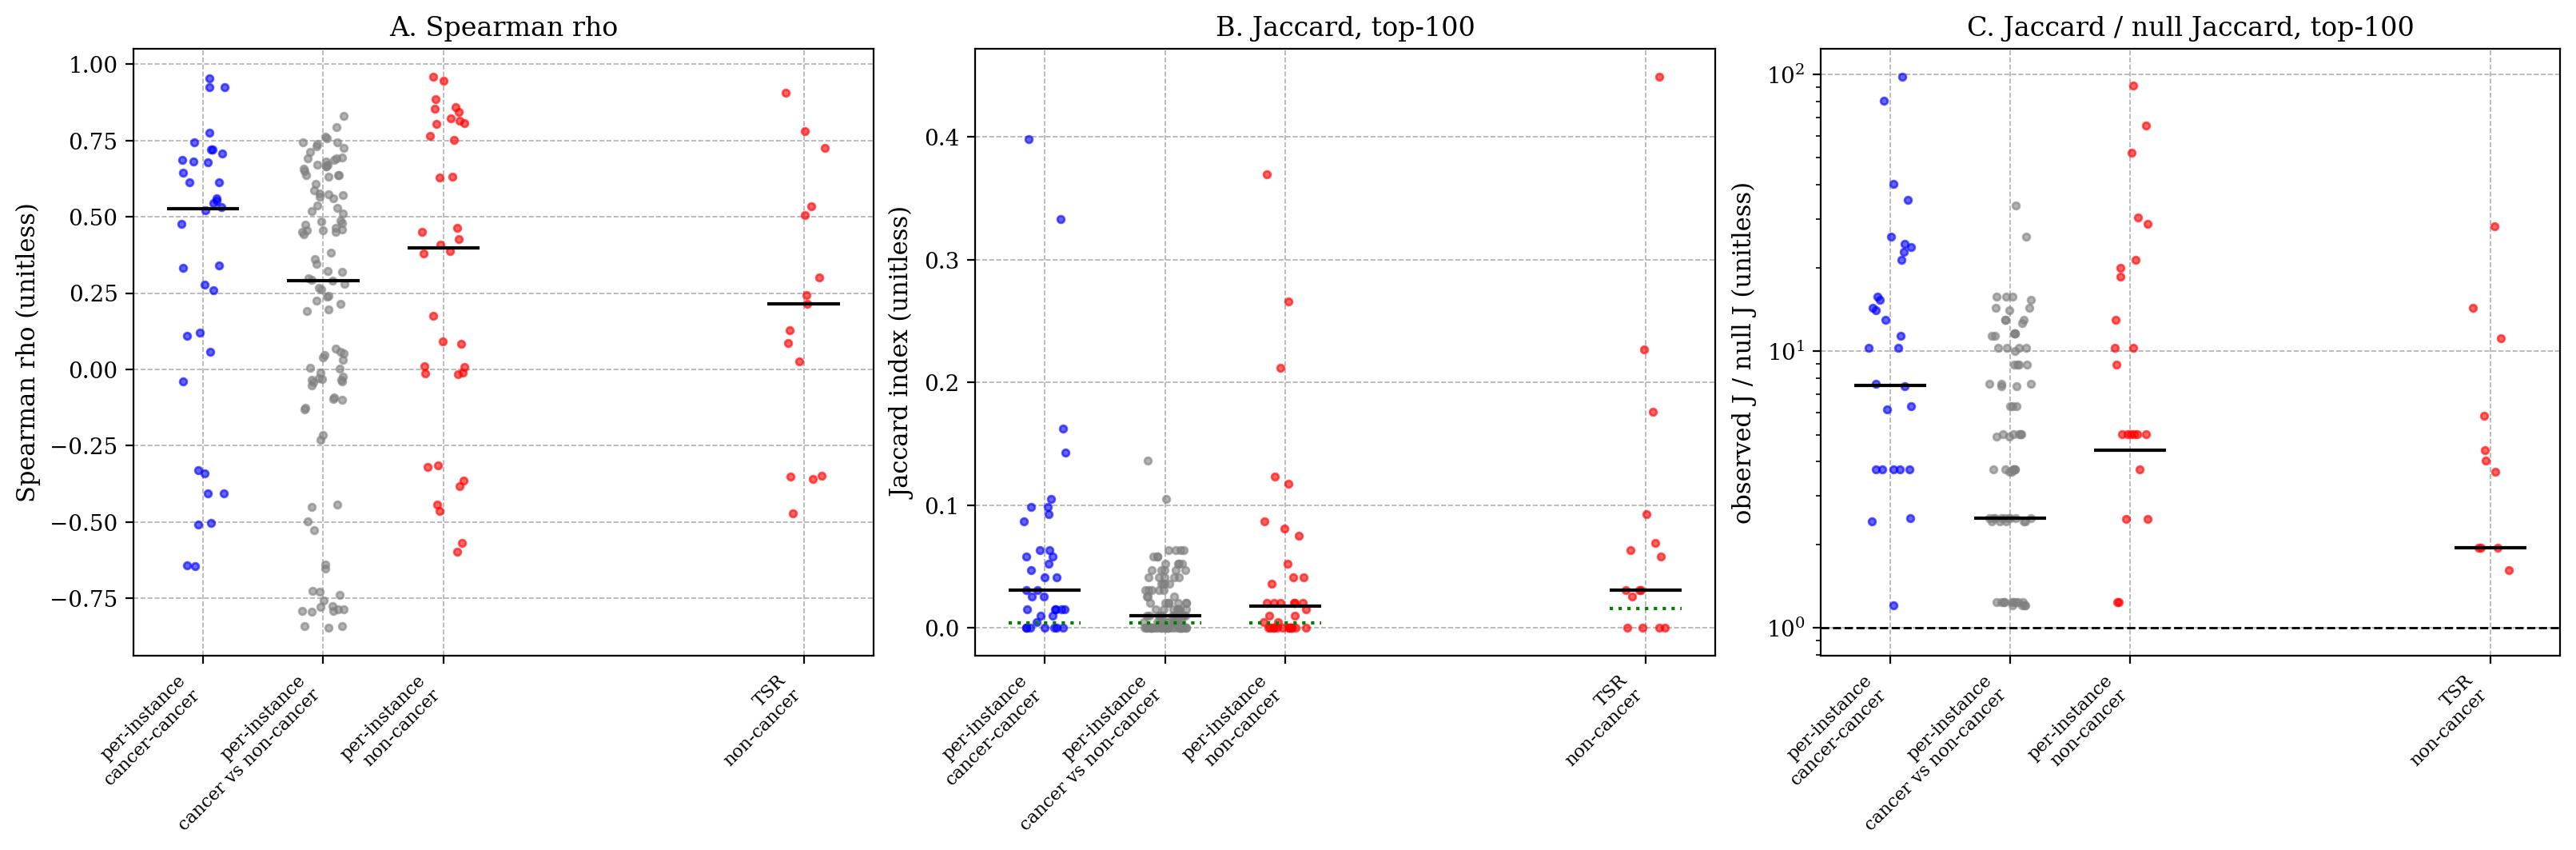

![Figure 5](../../../imgs/case_studies/cross_disease/cross_disease_pairs_by_class.png)

**Figure 5.** Each point is one (model, disease pair); black bar = median; in B the green dotted bar is the median hypergeometric null Jaccard of the class, in C the dashed line marks observed = null. Unfiltered drugs. Colour = pair class.

In [12]:
cls_order = ['cancer-cancer', 'cancer vs non-cancer', 'non-cancer']
cls_col = {'cancer-cancer': '#0000FF', 'cancer vs non-cancer': '#808080', 'non-cancer': '#FF0000'}
fig, axs = plt.subplots(1, 3, figsize=(16, 5.2), constrained_layout=True)
rng = np.random.default_rng(SEED)
for ax, (df, col, ttl, yl) in zip(axs, [(S, 'spearman', 'A. Spearman rho', 'Spearman rho (unitless)'),
                                        (J[J['k_label'] == '100'], 'jaccard', 'B. Jaccard, top-100', 'Jaccard index (unitless)'),
                                        (J[J['k_label'] == '100'], 'ratio_to_null', 'C. Jaccard / null Jaccard, top-100', 'observed J / null J (unitless)')]):
    d = df[df['variant'] == 'all']
    xt, xl = [], []
    for i, (fam, c) in enumerate([(f, c) for f in ['per-instance', 'TSR'] for c in cls_order]):
        v = d[(d['family'] == fam) & (d['pair_class'] == c)]
        if v.empty: continue
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v[col], s=10, color=cls_col[c], alpha=0.6)
        ax.hlines(v[col].median(), i - 0.3, i + 0.3, color='k')
        xt.append(i); xl.append(f'{fam}\n{c}')
    if col == 'ratio_to_null': ax.axhline(1, color='k', ls='--', lw=1)
    if col == 'jaccard':
        nn = d.groupby(['family', 'pair_class'])['jaccard_null'].median()
        for i, (fam, c) in enumerate([(f, c) for f in ['per-instance', 'TSR'] for c in cls_order]):
            if (fam, c) in nn.index: ax.hlines(nn[(fam, c)], i - 0.3, i + 0.3, color='g', ls=':')
    if col == 'ratio_to_null': ax.set_yscale('log')
    ax.set_xticks(xt); ax.set_xticklabels(xl, rotation=45, ha='right', fontsize=8); ax.set_title(ttl); ax.set_ylabel(yl)
show_fig(fig, 'pairs_by_class', 'Each point is one (model, disease pair); black bar = median; in B the green dotted bar is the median hypergeometric null Jaccard of the class, in C the dashed line marks observed = null. Unfiltered drugs. Colour = pair class.')

In [13]:
# per model: Spearman per pair
order_cfg = ['DEG', 'DEG_LM', 'mith', 'mith_LM', 'mith_pw']
d = S[(S['variant'] == 'all') & (S['family'] == 'per-instance')]
t = d.groupby(['config', 'score_type', 'pair_class'])['spearman'].median().unstack('pair_class').reindex(columns=cls_order).reset_index()
tt = S[(S['variant'] == 'all') & (S['family'] == 'TSR')].groupby(['config', 'score_type', 'pair_class'])['spearman'].median().unstack('pair_class').reindex(columns=cls_order).reset_index()
t = pd.concat([t, tt], ignore_index=True)
t['o'] = t['config'].map({c: i for i, c in enumerate(order_cfg)}); t = t.sort_values(['score_type', 'o']).drop(columns='o')
show_table(t, 'Median Spearman rho (unitless) of the disease pairs of each pair class, per method (configuration and score type); unfiltered drugs; empty = class not available for that method (TSR: three non-cancer diseases only).', fmt='{:.2f}')
save(t, 'spearman_by_method_and_class')

**Table 24.** Median Spearman rho (unitless) of the disease pairs of each pair class, per method (configuration and score type); unfiltered drugs; empty = class not available for that method (TSR: three non-cancer diseases only).

| config | score_type | cancer-cancer | cancer vs non-cancer | non-cancer |
|---|---|---|---|---|
| DEG | TSR |  |  | 0.13 |
| DEG_LM | TSR |  |  | 0.09 |
| mith | TSR |  |  | 0.22 |
| mith_LM | TSR |  |  | 0.02 |
| mith_pw | TSR |  |  | 0.78 |
| DEG | best | 0.68 | 0.46 | 0.38 |
| mith | best | 0.12 | 0.45 | 0.09 |
| mith_LM | best | 0.56 | 0.54 | 0.39 |
| mith_pw | best | 0.11 | -0.03 | 0.86 |
| DEG | sRGES | 0.55 | 0.24 | -0.02 |
| mith | sRGES | -0.33 | 0.19 | -0.38 |
| mith_LM | sRGES | 0.33 | 0.28 | -0.01 |
| mith_pw | sRGES | -0.41 | -0.78 | 0.82 |
| DEG | wsRGES | 0.55 | 0.26 | -0.01 |
| mith | wsRGES | -0.34 | 0.20 | -0.36 |
| mith_LM | wsRGES | 0.34 | 0.29 | 0.01 |
| mith_pw | wsRGES | -0.41 | -0.78 | 0.81 |

## 3. Instance-count bias and corticosteroids

`best` (and, less strongly, `sRGES`) of a drug profiled in many instances is more extreme by construction, so the same highly profiled drugs can lead every
disease. The comparison is repeated on shared drugs with n_instances >= `MIN_INSTANCES` in both diseases (`ge3inst`) and without corticosteroids (`no_cortico`).

In [14]:
v = S[S['family'] == 'per-instance'].groupby(['variant', 'pair_class']).agg(n_comparisons=('spearman', 'size'), median_n_shared=('n_shared', 'median'), spearman_median=('spearman', 'median'),
                                                                          spearman_min=('spearman', 'min'), spearman_max=('spearman', 'max')).reset_index()
show_table(v, 'Per-instance models: Spearman rho (unitless) by drug subset (variant) and pair class; median number of shared drugs (count of compounds) and median / min / max rho over (model, pair) combinations.', fmt='{:.2f}')
v2 = J[(J['family'] == 'per-instance') & (J['k_label'] == '100')].groupby(['variant', 'pair_class']).agg(jaccard_median=('jaccard', 'median'), null_median=('jaccard_null', 'median'), ratio_median=('ratio_to_null', 'median')).reset_index()
show_table(v2, 'Per-instance models: Jaccard index of the top-100 sets (unitless) by drug subset and pair class: median observed, median hypergeometric null, median observed / null.', fmt='{:.3f}')
vb = S[(S['family'] == 'per-instance')].groupby(['score_type', 'variant'])['spearman'].median().unstack('variant')
show_table(vb.reset_index(), 'Per-instance models: median Spearman rho (unitless) over all disease pairs and configurations, per score type and drug subset.', fmt='{:.2f}')
v3 = S[S['family'] == 'TSR'].groupby(['variant', 'pair_class']).agg(n_comparisons=('spearman', 'size'), spearman_median=('spearman', 'median'), spearman_min=('spearman', 'min'), spearman_max=('spearman', 'max')).reset_index()
show_table(v3, 'TSR models: Spearman rho (unitless) with and without corticosteroids (n_instances is not defined for TSR).', fmt='{:.2f}')
save(v, 'summary_variants_spearman'); save(v2, 'summary_variants_jaccard_k100')

**Table 25.** Per-instance models: Spearman rho (unitless) by drug subset (variant) and pair class; median number of shared drugs (count of compounds) and median / min / max rho over (model, pair) combinations.

| variant | pair_class | n_comparisons | median_n_shared | spearman_median | spearman_min | spearman_max |
|---|---|---|---|---|---|---|
| all | cancer vs non-cancer | 108 | 12440 | 0.29 | -0.85 | 0.83 |
| all | cancer-cancer | 36 | 12440 | 0.53 | -0.64 | 0.95 |
| all | non-cancer | 36 | 12440 | 0.40 | -0.60 | 0.96 |
| ge3inst | cancer vs non-cancer | 108 | 5310 | 0.28 | -0.83 | 0.76 |
| ge3inst | cancer-cancer | 36 | 5310 | 0.48 | -0.61 | 0.92 |
| ge3inst | non-cancer | 36 | 5310 | 0.32 | -0.65 | 0.95 |
| ge3inst_no_cortico | cancer vs non-cancer | 108 | 5281 | 0.28 | -0.83 | 0.76 |
| ge3inst_no_cortico | cancer-cancer | 36 | 5281 | 0.48 | -0.61 | 0.92 |
| ge3inst_no_cortico | non-cancer | 36 | 5281 | 0.32 | -0.65 | 0.95 |
| no_cortico | cancer vs non-cancer | 108 | 12407 | 0.29 | -0.85 | 0.83 |
| no_cortico | cancer-cancer | 36 | 12407 | 0.53 | -0.64 | 0.95 |
| no_cortico | non-cancer | 36 | 12407 | 0.40 | -0.60 | 0.96 |

**Table 26.** Per-instance models: Jaccard index of the top-100 sets (unitless) by drug subset and pair class: median observed, median hypergeometric null, median observed / null.

| variant | pair_class | jaccard_median | null_median | ratio_median |
|---|---|---|---|---|
| all | cancer vs non-cancer | 0.010 | 0.004 | 2.491 |
| all | cancer-cancer | 0.031 | 0.004 | 7.542 |
| all | non-cancer | 0.018 | 0.004 | 4.389 |
| ge3inst | cancer vs non-cancer | 0.026 | 0.010 | 2.684 |
| ge3inst | cancer-cancer | 0.053 | 0.010 | 5.522 |
| ge3inst | non-cancer | 0.031 | 0.010 | 3.238 |
| ge3inst_no_cortico | cancer vs non-cancer | 0.026 | 0.010 | 2.669 |
| ge3inst_no_cortico | cancer-cancer | 0.055 | 0.010 | 5.775 |
| ge3inst_no_cortico | non-cancer | 0.031 | 0.010 | 3.220 |
| no_cortico | cancer vs non-cancer | 0.010 | 0.004 | 2.484 |
| no_cortico | cancer-cancer | 0.031 | 0.004 | 7.521 |
| no_cortico | non-cancer | 0.018 | 0.004 | 4.378 |

**Table 27.** Per-instance models: median Spearman rho (unitless) over all disease pairs and configurations, per score type and drug subset.

| score_type | all | ge3inst | ge3inst_no_cortico | no_cortico |
|---|---|---|---|---|
| best | 0.47 | 0.31 | 0.31 | 0.47 |
| sRGES | 0.25 | 0.29 | 0.29 | 0.25 |
| wsRGES | 0.27 | 0.30 | 0.31 | 0.27 |

**Table 28.** TSR models: Spearman rho (unitless) with and without corticosteroids (n_instances is not defined for TSR).

| variant | pair_class | n_comparisons | spearman_median | spearman_min | spearman_max |
|---|---|---|---|---|---|
| all | non-cancer | 15 | 0.22 | -0.47 | 0.91 |
| no_cortico | non-cancer | 15 | 0.22 | -0.47 | 0.91 |

## 4. Per-drug behaviour across diseases

For each family, every drug scored in all diseases of the family has a percentile in each disease (within the model). The mean and the SD of these percentiles
across diseases are computed per model; a drug with mean <= `MEAN_MAX` and SD <= `SD_MAX` is *flagged* in that model. A drug flagged in at least `FLAG_FRAC` of the models of its family is listed as a **flagged drug**: it is ranked among the strongest reversers in every disease under several methods. For independent uniform percentiles the expected mean is 50 and the expected SD about 28.9 percentile points;
the number of drugs flagged after permuting each disease's percentiles across drugs (`N_PERM` = 1000 permutations) gives a null count. This null tests only the independence of the diseases' rankings; it does not test a drug-specific property, because the observed rank correlations between diseases (section 2) already make low mean and low SD more frequent than under independence. The TCGA diseases are not independent of one another (same signature pipeline and LINCS pool). Models are correlated, so the fraction of flagging models is descriptive.


In [15]:
def drug_stats(family):
    sub = R[R['family'] == family]
    full = [d for d in DISEASES if sub[sub['disease'] == d].shape[0] > 0]
    recs, perm = [], []
    rng = np.random.default_rng(SEED)
    for slc, g in sub.groupby('model', observed=True):
        P = g.pivot(index='drug_key', columns='disease', values='pct')
        ds = [d for d in full if d in P.columns]
        if len(ds) != len(full): continue
        P = P[ds].dropna()
        N = g.pivot(index='drug_key', columns='disease', values='n_instances')[ds].reindex(P.index)
        r = pd.DataFrame({'model': slc, 'drug_key': P.index, 'mean_pct': P.mean(axis=1).values, 'sd_pct': P.std(axis=1, ddof=1).values,
                          'min_n_inst': N.min(axis=1).values})
        for d in ds: r['pct_' + d] = P[d].values
        recs.append(r)
        flagged = ((r['mean_pct'] <= MEAN_MAX) & (r['sd_pct'] <= SD_MAX)).sum()
        pc = []
        arr = P.values
        for _ in range(N_PERM):
            Q = np.column_stack([rng.permutation(arr[:, j]) for j in range(arr.shape[1])])
            pc.append(((Q.mean(axis=1) <= MEAN_MAX) & (Q.std(axis=1, ddof=1) <= SD_MAX)).sum())
        perm.append({'family': family, 'model': slc, 'n_drugs': len(P), 'flagged_observed': int(flagged),
                     'flagged_null_mean': float(np.mean(pc)), 'flagged_null_max': int(np.max(pc))})
    return pd.concat(recs, ignore_index=True), pd.DataFrame(perm), full

DS, PM, DF = {}, [], {}
for fam in ['per-instance', 'TSR']:
    DS[fam], pm, DF[fam] = drug_stats(fam); PM.append(pm)
PM = pd.concat(PM, ignore_index=True)
show_table(PM, f'Flagged drugs per model: drugs scored in all diseases of the family (count of compounds), drugs with mean percentile <= {MEAN_MAX:g} and SD <= {SD_MAX:g} (percentile points), and the same count after permuting each disease\'s percentiles across drugs (mean and maximum over {N_PERM} permutations).', fmt='{:.1f}')
save(PM, 'promiscuity_vs_permutation')

**Table 29.** Flagged drugs per model: drugs scored in all diseases of the family (count of compounds), drugs with mean percentile <= 10 and SD <= 10 (percentile points), and the same count after permuting each disease's percentiles across drugs (mean and maximum over 1000 permutations).

| family | model | n_drugs | flagged_observed | flagged_null_mean | flagged_null_max |
|---|---|---|---|---|---|
| per-instance | DEG_best | 12440 | 328 | 0.7 | 6 |
| per-instance | DEG_sRGES | 12440 | 34 | 0.7 | 4 |
| per-instance | DEG_wsRGES | 12166 | 24 | 0.7 | 4 |
| per-instance | mith_LM_best | 12440 | 296 | 0.7 | 4 |
| per-instance | mith_LM_sRGES | 12440 | 41 | 0.6 | 5 |
| per-instance | mith_LM_wsRGES | 12166 | 32 | 0.7 | 4 |
| per-instance | mith_best | 12440 | 153 | 0.7 | 5 |
| per-instance | mith_pw_best | 12440 | 358 | 0.6 | 4 |
| per-instance | mith_pw_sRGES | 12440 | 1 | 0.6 | 5 |
| per-instance | mith_pw_wsRGES | 12166 | 0 | 0.6 | 4 |
| per-instance | mith_sRGES | 12440 | 0 | 0.7 | 5 |
| per-instance | mith_wsRGES | 12166 | 0 | 0.6 | 4 |
| TSR | DEG_LM_TSR | 3221 | 11 | 12.9 | 27 |
| TSR | DEG_TSR | 3221 | 12 | 12.9 | 24 |
| TSR | mith_LM_TSR | 3221 | 7 | 12.7 | 25 |
| TSR | mith_TSR | 3221 | 14 | 13.0 | 24 |
| TSR | mith_pw_TSR | 3221 | 247 | 12.8 | 27 |

In [16]:
def agg_drug(family):
    d = DS[family]
    d = d.assign(flag=(d['mean_pct'] <= MEAN_MAX) & (d['sd_pct'] <= SD_MAX))
    pcols = [c for c in d.columns if c.startswith('pct_')]
    a = d.groupby('drug_key').agg(n_models=('model', 'size'), mean_pct=('mean_pct', 'median'), sd_pct=('sd_pct', 'median'),
                                  frac_models_flagged=('flag', 'mean'), min_n_inst=('min_n_inst', 'median'),
                                  **{c: (c, 'median') for c in pcols}).reset_index()
    a['family'] = family
    a['flagged'] = a['frac_models_flagged'] >= FLAG_FRAC
    a['rank_by_mean_pct'] = a['mean_pct'].rank(method='min')
    return a.sort_values(['frac_models_flagged', 'mean_pct'], ascending=[False, True])
AG = {f: agg_drug(f) for f in DS}
ALL = pd.concat(AG.values(), ignore_index=True)
save(ALL, 'drug_percentile_across_diseases')
for fam, a in AG.items():
    f = a[a['flagged']]
    ncol = [c for c in a.columns if c.startswith('pct_')]
    top = f.head(25)[['drug_key', 'n_models', 'mean_pct', 'sd_pct', 'frac_models_flagged', 'min_n_inst'] + ncol]
    show_table(top, f'{fam}: the {len(top)} flagged drugs with the highest fraction of flagging models (of {len(f)} drugs flagged in at least {FLAG_FRAC:.0%} of the models, {len(a)} drugs compared over {len(DF[fam])} diseases). n_models = models in which the drug is scored in every disease; mean_pct and sd_pct = median over models of the mean / SD of percentile across diseases (percentile points; a drug is flagged within a model on the mean and SD of that model, so the medians need not meet the thresholds); frac_models_flagged = fraction of those models where the drug meets the threshold; min_n_inst = median over models of the smallest n_instances across diseases (per-instance only); pct_[disease] = median percentile in that disease (0-100, low = strong reversal).', fmt='{:.1f}')
    if fam == 'TSR':
        display(Markdown('For TSR the number of flagged drugs per model is at or below the permutation null (Table of flagged drugs per model), except where the table shows otherwise; the TSR list is shown for completeness and carries no further reading.'))
    if fam == 'per-instance':
        g3 = f[f['min_n_inst'] >= MIN_INSTANCES]
        display(Markdown(f'Of the {len(f)} per-instance flagged drugs, {len(g3)} have a median smallest n_instances >= {MIN_INSTANCES}.'))

**Table 30.** per-instance: the 25 flagged drugs with the highest fraction of flagging models (of 146 drugs flagged in at least 25% of the models, 12440 drugs compared over 6 diseases). n_models = models in which the drug is scored in every disease; mean_pct and sd_pct = median over models of the mean / SD of percentile across diseases (percentile points; a drug is flagged within a model on the mean and SD of that model, so the medians need not meet the thresholds); frac_models_flagged = fraction of those models where the drug meets the threshold; min_n_inst = median over models of the smallest n_instances across diseases (per-instance only); pct_[disease] = median percentile in that disease (0-100, low = strong reversal).

| drug_key | n_models | mean_pct | sd_pct | frac_models_flagged | min_n_inst | pct_asthma | pct_IPF | pct_ALS | pct_BRCA | pct_LIHC | pct_COAD |
|---|---|---|---|---|---|---|---|---|---|---|---|
| teniposide | 12 | 18.4 | 16.9 | 0.3 | 91 | 32.6 | 12.6 | 15.7 | 5.9 | 13.0 | 16.3 |
| pyrviniumpamoate | 12 | 23.6 | 17.8 | 0.3 | 64 | 18.6 | 13.9 | 21.3 | 11.6 | 5.3 | 37.6 |
| trichostatina | 12 | 24.2 | 18.5 | 0.3 | 803 | 41.2 | 10.5 | 37.1 | 4.9 | 13.5 | 5.5 |
| idarubicin | 12 | 24.3 | 16.8 | 0.3 | 86 | 37.5 | 25.1 | 22.1 | 8.0 | 13.1 | 14.2 |
| etoposide | 12 | 24.8 | 11.8 | 0.3 | 35 | 41.3 | 26.9 | 19.0 | 21.6 | 14.2 | 19.1 |
| wortmannin | 12 | 25.0 | 8.3 | 0.3 | 582 | 43.2 | 4.9 | 14.2 | 19.8 | 28.3 | 30.9 |
| vorinostat | 12 | 28.9 | 18.5 | 0.3 | 858 | 47.1 | 12.7 | 43.4 | 9.0 | 22.5 | 8.4 |
| brdk56647759 | 12 | 30.1 | 18.9 | 0.3 | 1 | 61.8 | 2.8 | 16.8 | 20.0 | 24.1 | 19.9 |
| gemcitabine | 12 | 30.2 | 13.0 | 0.3 | 82 | 49.6 | 17.6 | 30.1 | 16.0 | 23.6 | 24.4 |
| cd437 | 12 | 31.2 | 16.9 | 0.3 | 67 | 46.9 | 34.5 | 26.9 | 13.1 | 9.2 | 35.2 |
| sirolimus | 12 | 31.5 | 7.4 | 0.3 | 285 | 37.9 | 14.8 | 27.0 | 29.4 | 36.2 | 33.3 |
| erlotinib | 12 | 32.5 | 9.0 | 0.3 | 32 | 29.4 | 25.8 | 36.9 | 27.9 | 29.0 | 28.8 |
| bi2536 | 12 | 32.7 | 15.1 | 0.3 | 102 | 29.2 | 13.1 | 25.7 | 11.6 | 25.6 | 28.5 |
| ly294002 | 12 | 32.7 | 8.5 | 0.3 | 180 | 34.0 | 15.7 | 32.2 | 29.4 | 35.3 | 38.0 |
| brdk37728465 | 12 | 33.0 | 16.3 | 0.3 | 1 | 17.7 | 6.1 | 21.9 | 28.1 | 23.1 | 58.4 |
| nvptae684 | 12 | 33.1 | 13.1 | 0.3 | 67 | 45.3 | 22.7 | 25.7 | 19.8 | 40.7 | 29.4 |
| brdk70551857 | 12 | 33.4 | 28.0 | 0.3 | 1 | 17.7 | 6.4 | 5.6 | 13.6 | 15.9 | 73.1 |
| pp30 | 12 | 33.7 | 16.3 | 0.3 | 46 | 47.8 | 11.5 | 27.9 | 31.5 | 30.6 | 29.0 |
| serdemetan | 12 | 33.7 | 11.8 | 0.3 | 47 | 48.1 | 28.8 | 19.2 | 25.0 | 22.4 | 43.1 |
| mg132 | 12 | 34.5 | 12.5 | 0.3 | 47 | 43.4 | 24.1 | 45.3 | 14.3 | 18.9 | 41.1 |
| bms536924 | 12 | 35.4 | 9.9 | 0.3 | 71 | 46.2 | 18.0 | 14.9 | 34.9 | 44.9 | 36.1 |
| brdk78062244 | 12 | 35.5 | 9.0 | 0.3 | 25 | 50.0 | 33.8 | 24.7 | 29.9 | 20.3 | 37.4 |
| mepacrine | 12 | 36.7 | 7.3 | 0.3 | 65 | 39.9 | 29.0 | 41.1 | 31.5 | 34.4 | 32.6 |
| gefitinib | 12 | 37.1 | 7.0 | 0.3 | 41 | 33.5 | 25.2 | 40.1 | 32.7 | 41.4 | 37.6 |
| ldn193189 | 12 | 37.4 | 9.8 | 0.3 | 61 | 36.7 | 39.2 | 29.6 | 37.1 | 25.3 | 54.8 |

Of the 146 per-instance flagged drugs, 138 have a median smallest n_instances >= 3.

**Table 31.** TSR: the 10 flagged drugs with the highest fraction of flagging models (of 10 drugs flagged in at least 25% of the models, 3221 drugs compared over 3 diseases). n_models = models in which the drug is scored in every disease; mean_pct and sd_pct = median over models of the mean / SD of percentile across diseases (percentile points; a drug is flagged within a model on the mean and SD of that model, so the medians need not meet the thresholds); frac_models_flagged = fraction of those models where the drug meets the threshold; min_n_inst = median over models of the smallest n_instances across diseases (per-instance only); pct_[disease] = median percentile in that disease (0-100, low = strong reversal).

| drug_key | n_models | mean_pct | sd_pct | frac_models_flagged | min_n_inst | pct_asthma | pct_IPF | pct_ALS |
|---|---|---|---|---|---|---|---|---|
| brdk69496360 | 5 | 7.4 | 4.6 | 0.8 |  | 4.5 | 4.1 | 8.8 |
| ku0063794 | 5 | 7.5 | 6.4 | 0.6 |  | 13.3 | 0.8 | 8.4 |
| cyanopindolol | 5 | 11.1 | 7.8 | 0.4 |  | 9.2 | 16.0 | 18.3 |
| tyrphostinag126 | 5 | 11.3 | 17.6 | 0.4 |  | 1.1 | 0.5 | 33.3 |
| torin2 | 5 | 16.5 | 14.1 | 0.4 |  | 42.3 | 4.2 | 1.7 |
| nvpbez235 | 5 | 17.9 | 9.8 | 0.4 |  | 41.8 | 1.5 | 1.2 |
| ricinine | 5 | 18.5 | 9.5 | 0.4 |  | 12.3 | 17.9 | 16.9 |
| osi027 | 5 | 19.7 | 15.1 | 0.4 |  | 54.1 | 0.9 | 11.2 |
| azd8055 | 5 | 20.1 | 11.5 | 0.4 |  | 39.8 | 1.4 | 8.7 |
| jw7241 | 5 | 21.7 | 6.4 | 0.4 |  | 22.4 | 0.4 | 3.2 |

For TSR the number of flagged drugs per model is at or below the permutation null (Table of flagged drugs per model), except where the table shows otherwise; the TSR list is shown for completeness and carries no further reading.

In [17]:
FAM = {'protein-synthesis inhibitors': ['homoharringtonine', 'cephaeline', 'emetine'],
       'cardiac glycosides': ['bufalin', 'proscillaridin', 'digoxin', 'strophanthidin', 'cymarin']}
rows = []
for fam, a in AG.items():
    a = a.set_index('drug_key'); pc = [c for c in a.columns if c.startswith('pct_')]
    for cls, names in FAM.items():
        for nm in names:
            k = key([nm])[0]
            if k in a.index:
                r = a.loc[k]
                rows.append({'family': fam, 'class': cls, 'drug': nm, 'n_models': int(r['n_models']), 'mean_pct': r['mean_pct'], 'sd_pct': r['sd_pct'],
                             'rank_of_mean_pct': int(r['rank_by_mean_pct']), 'n_drugs': len(a), 'frac_models_flagged': r['frac_models_flagged'],
                             'flagged': bool(r['flagged']), **{c: r[c] for c in pc}})
            else:
                rows.append({'family': fam, 'class': cls, 'drug': nm, 'n_models': 0})
FD = pd.DataFrame(rows)
save(FD, 'drug_classes_check')
show_table(FD.round(2), 'Protein-synthesis inhibitors and cardiac glycosides across diseases: median over models of the mean and SD of percentile across diseases (percentile points), rank of the mean percentile among the n_drugs compared (1 = lowest), fraction of models where the drug is flagged, and median percentile per disease (0-100). n_models = 0: drug not scored in every disease of the family.', fmt='{:.1f}')

**Table 32.** Protein-synthesis inhibitors and cardiac glycosides across diseases: median over models of the mean and SD of percentile across diseases (percentile points), rank of the mean percentile among the n_drugs compared (1 = lowest), fraction of models where the drug is flagged, and median percentile per disease (0-100). n_models = 0: drug not scored in every disease of the family.

| family | class | drug | n_models | mean_pct | sd_pct | rank_of_mean_pct | n_drugs | frac_models_flagged | flagged | pct_asthma | pct_IPF | pct_ALS | pct_BRCA | pct_LIHC | pct_COAD |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| per-instance | protein-synthesis inhibitors | homoharringtonine | 12 | 22.2 | 17.5 | 16 | 12440 | 0.2 | False | 14.2 | 0.9 | 23.4 | 28.7 | 19.3 | 50.8 |
| per-instance | protein-synthesis inhibitors | cephaeline | 12 | 28.6 | 21.6 | 229 | 12440 | 0.1 | False | 12.0 | 1.0 | 30.4 | 41.1 | 31 | 70.3 |
| per-instance | protein-synthesis inhibitors | emetine | 12 | 28.1 | 18.9 | 188 | 12440 | 0.2 | False | 12 | 4.1 | 30.4 | 35.6 | 26.0 | 66.2 |
| per-instance | cardiac glycosides | bufalin | 12 | 32.5 | 26.2 | 722 | 12440 | 0.1 | False | 29.7 | 3.8 | 15.5 | 32.8 | 16.4 | 73.9 |
| per-instance | cardiac glycosides | proscillaridin | 12 | 28.9 | 22.4 | 262 | 12440 | 0.2 | False | 31.9 | 4.2 | 23.2 | 24.1 | 16.3 | 60.2 |
| per-instance | cardiac glycosides | digoxin | 12 | 31.3 | 21.9 | 535 | 12440 | 0.1 | False | 32.3 | 6.0 | 19.8 | 24.6 | 18.1 | 61.5 |
| per-instance | cardiac glycosides | strophanthidin | 12 | 32.8 | 25.2 | 789 | 12440 | 0.1 | False | 32.0 | 5.9 | 20.2 | 29.1 | 16.5 | 60.7 |
| per-instance | cardiac glycosides | cymarin | 12 | 28.4 | 21.2 | 212 | 12440 | 0.0 | False | 30.1 | 5.9 | 17.6 | 29.7 | 21.9 | 58.3 |
| TSR | protein-synthesis inhibitors | homoharringtonine | 5 | 21.6 | 36.4 | 79 | 3221 | 0.2 | False | 0.3 | 0.1 | 63.6 |  |  |  |
| TSR | protein-synthesis inhibitors | cephaeline | 5 | 23.7 | 40.5 | 136 | 3221 | 0.2 | False | 0.2 | 0.4 | 70.5 |  |  |  |
| TSR | protein-synthesis inhibitors | emetine | 5 | 23.6 | 38.8 | 134 | 3221 | 0.2 | False | 0.8 | 0.5 | 68.4 |  |  |  |
| TSR | cardiac glycosides | bufalin | 5 | 18.4 | 24.4 | 42 | 3221 | 0.2 | False | 6.2 | 8.7 | 45.1 |  |  |  |
| TSR | cardiac glycosides | proscillaridin | 5 | 31.4 | 34.0 | 385 | 3221 | 0.0 | False | 18.4 | 2.6 | 64.5 |  |  |  |
| TSR | cardiac glycosides | digoxin | 5 | 28.6 | 27.2 | 267 | 3221 | 0.0 | False | 17.1 | 8.0 | 67.8 |  |  |  |
| TSR | cardiac glycosides | strophanthidin | 5 | 25.2 | 34.9 | 163 | 3221 | 0.2 | False | 8.2 | 5.6 | 65.1 |  |  |  |
| TSR | cardiac glycosides | cymarin | 5 | 29.2 | 23.9 | 283 | 3221 | 0.2 | False | 12.8 | 5.7 | 46.7 |  |  |  |

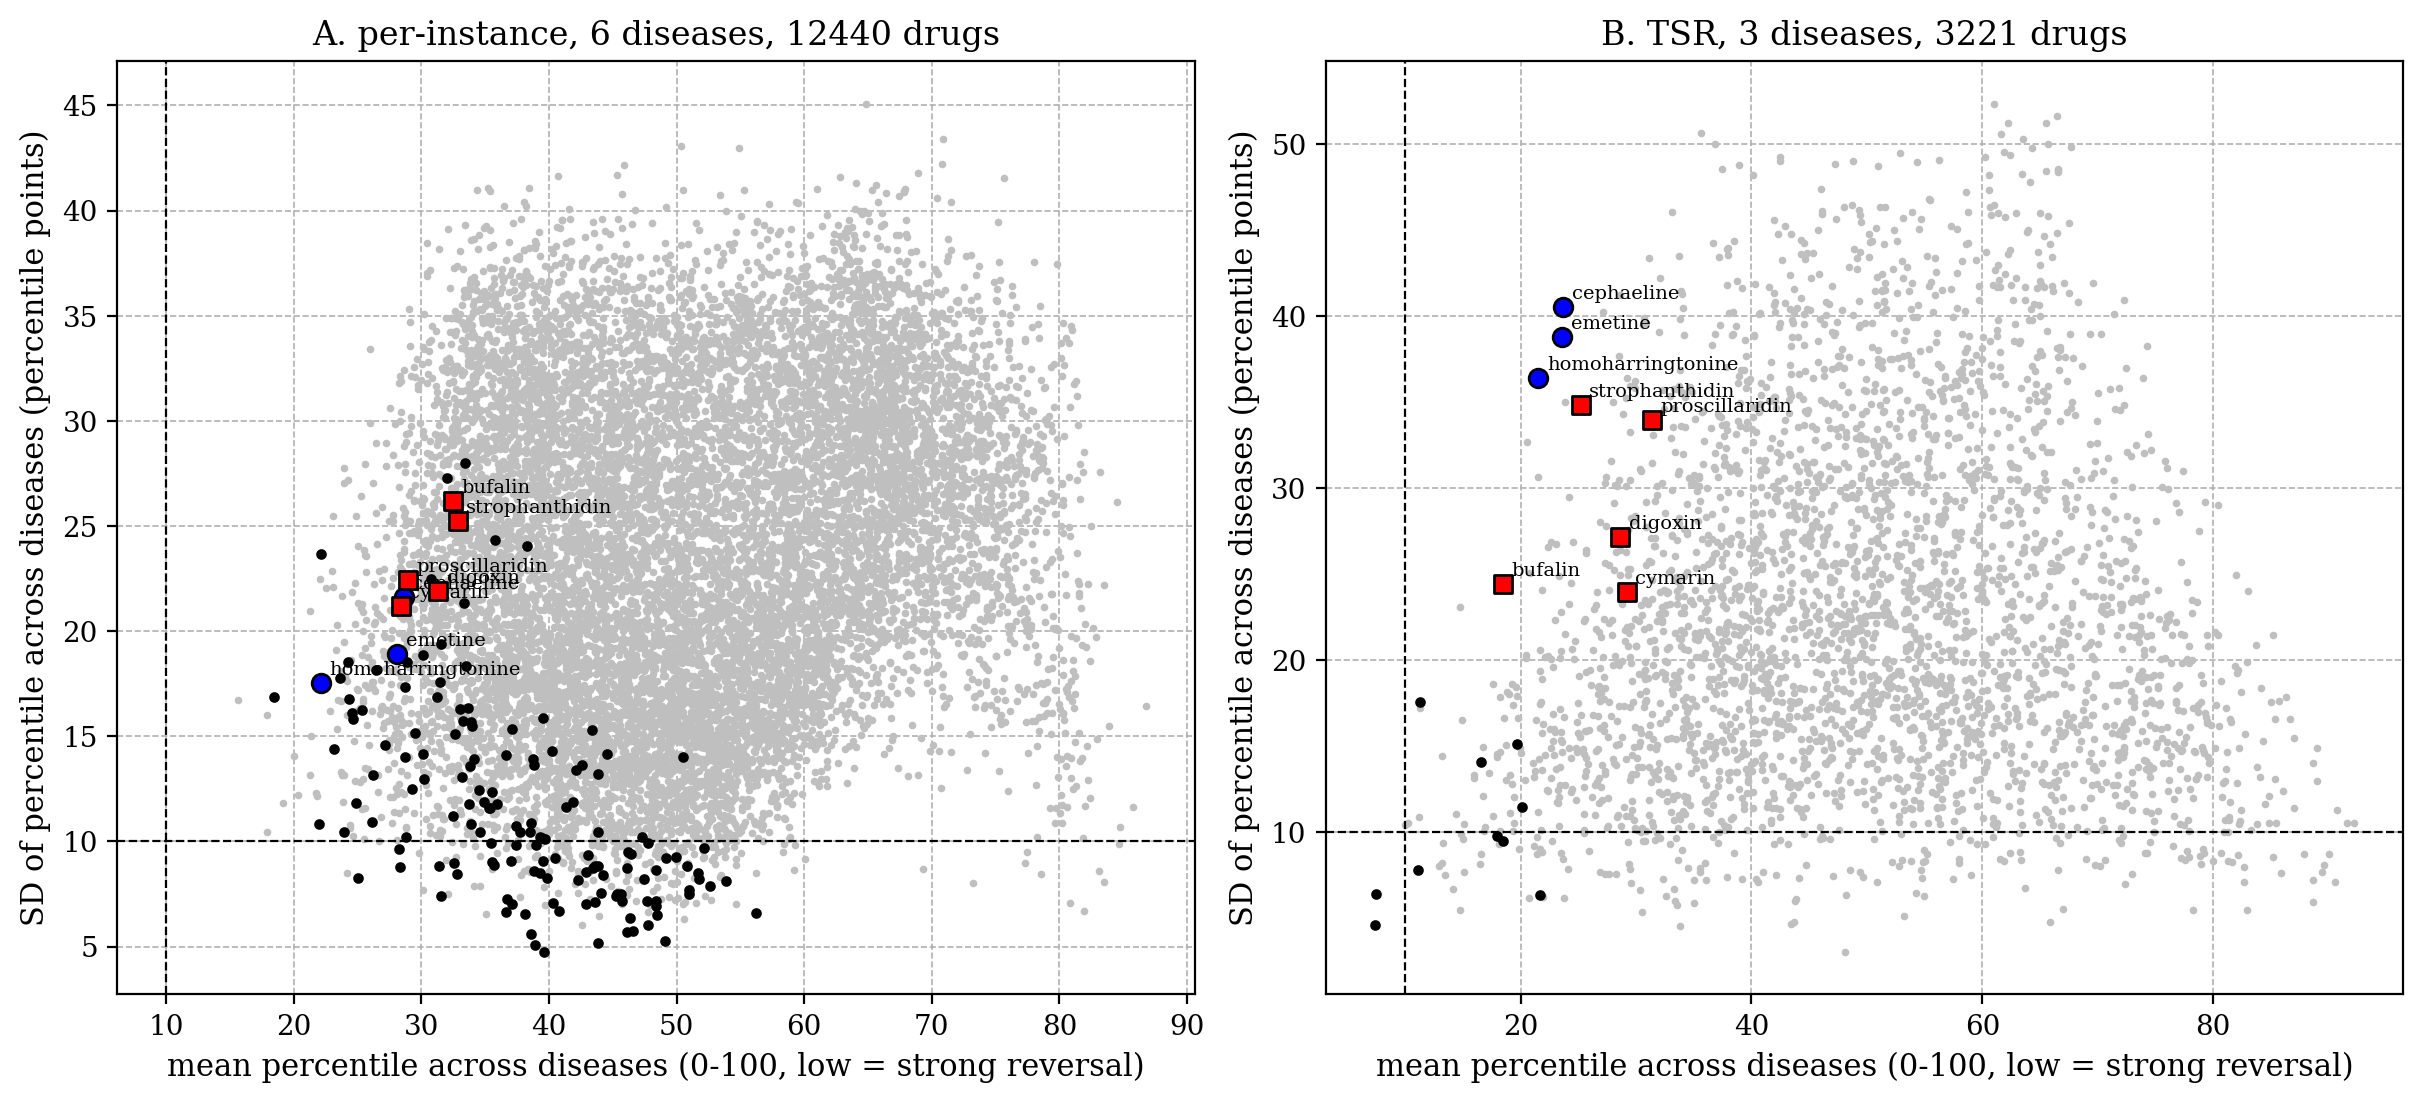

![Figure 6](../../../imgs/case_studies/cross_disease/cross_disease_drug_percentile_mean_sd.png)

**Figure 6.** Each point is a drug: median over models of the mean (x) and SD (y) of its percentile across diseases. Black = flagged drug (mean and SD below the dashed thresholds); blue circles = protein-synthesis inhibitors, red squares = cardiac glycosides.

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5.4), constrained_layout=True)
hl = {k: ('#0000FF', 'o') for k in key(FAM['protein-synthesis inhibitors'])}
hl.update({k: ('#FF0000', 's') for k in key(FAM['cardiac glycosides'])})
for ax, fam in zip(axs, ['per-instance', 'TSR']):
    a = AG[fam]
    ax.scatter(a['mean_pct'], a['sd_pct'], s=3, color='0.75', rasterized=True)
    f = a[a['flagged']]
    ax.scatter(f['mean_pct'], f['sd_pct'], s=8, color='k')
    for k, (c, m) in hl.items():
        r = a[a['drug_key'] == k]
        if len(r):
            ax.scatter(r['mean_pct'], r['sd_pct'], s=45, color=c, marker=m, edgecolor='k', zorder=5)
            ax.annotate(k, (r['mean_pct'].iloc[0], r['sd_pct'].iloc[0]), fontsize=7, xytext=(3, 3), textcoords='offset points')
    ax.axvline(MEAN_MAX, color='k', ls='--', lw=0.8); ax.axhline(SD_MAX, color='k', ls='--', lw=0.8)
    ax.set_xlabel('mean percentile across diseases (0-100, low = strong reversal)'); ax.set_ylabel('SD of percentile across diseases (percentile points)')
    ax.set_title(f'{"AB"[["per-instance", "TSR"].index(fam)]}. {fam}, {len(DF[fam])} diseases, {len(a)} drugs')
show_fig(fig, 'drug_percentile_mean_sd', 'Each point is a drug: median over models of the mean (x) and SD (y) of its percentile across diseases. Black = flagged drug (mean and SD below the dashed thresholds); blue circles = protein-synthesis inhibitors, red squares = cardiac glycosides.')

## 5. Summary of the numbers

In [19]:
lines = []
for fam in ['per-instance', 'TSR']:
    for c in cls_order:
        v = S[(S['family'] == fam) & (S['variant'] == 'all') & (S['pair_class'] == c)]['spearman']
        j = J[(J['family'] == fam) & (J['variant'] == 'all') & (J['pair_class'] == c) & (J['k_label'] == '100')]
        if len(v): lines.append(f'- {fam}, {c}: Spearman rho median {v.median():.2f} (range {v.min():.2f} to {v.max():.2f}, n = {len(v)} model-pairs); top-100 Jaccard median {j["jaccard"].median():.3f} vs null {j["jaccard_null"].median():.4f}.')
pw = S[(S['variant'] == 'all') & (S['config'] == 'mith_pw')]
lines.append(f'- Methods with configuration `mith_pw`: median rho over all model-pairs {pw["spearman"].median():.2f}, against {S[(S["variant"] == "all") & (S["config"] != "mith_pw")]["spearman"].median():.2f} for the other configurations; its rankings split the diseases into two groups with opposite-sign rho and chance-level top-5% overlap across the split. This pattern is unexplained: it may be a score-scale or sign artefact of the pathway-level score or of the LIHC / COAD runs, and it has no biological reading until the mith_pw score distributions per disease are inspected.')
nf = PM.groupby('family').apply(lambda d: f'flagged per model median {d["flagged_observed"].median():.0f} (permutation null median {d["flagged_null_mean"].median():.1f})', include_groups=False)
lines += [f'- Drugs flagged per model, {k}: {v}.' for k, v in nf.items()]
display(Markdown('\n'.join(lines)))

- per-instance, cancer-cancer: Spearman rho median 0.53 (range -0.64 to 0.95, n = 36 model-pairs); top-100 Jaccard median 0.031 vs null 0.0041.
- per-instance, cancer vs non-cancer: Spearman rho median 0.29 (range -0.85 to 0.83, n = 108 model-pairs); top-100 Jaccard median 0.010 vs null 0.0041.
- per-instance, non-cancer: Spearman rho median 0.40 (range -0.60 to 0.96, n = 36 model-pairs); top-100 Jaccard median 0.018 vs null 0.0041.
- TSR, non-cancer: Spearman rho median 0.22 (range -0.47 to 0.91, n = 15 model-pairs); top-100 Jaccard median 0.031 vs null 0.0158.
- Methods with configuration `mith_pw`: median rho over all model-pairs 0.38, against 0.32 for the other configurations; its rankings split the diseases into two groups with opposite-sign rho and chance-level top-5% overlap across the split. This pattern is unexplained: it may be a score-scale or sign artefact of the pathway-level score or of the LIHC / COAD runs, and it has no biological reading until the mith_pw score distributions per disease are inspected.
- Drugs flagged per model, TSR: flagged per model median 12 (permutation null median 12.9).
- Drugs flagged per model, per-instance: flagged per model median 33 (permutation null median 0.7).

## 6. Limits

- A low cross-disease correlation is not by itself an advantage of a method: a method returning noise would also correlate 0 across diseases and would look the most disease-specific.
  The informative second half of the test is a high concordance between two independent datasets of the same disease, which are not available here; the comparison above
  therefore describes how much of each ranking is shared across diseases, not which method is better.
- The TSR and per-instance routes differ in the drug collapse and in the LINCS instance pool (level 3 vs gold-set level 5), so family-level differences mix both effects.
- The per-instance scores of all six diseases use the `"corrected"` offset assignment. The wsRGES weights come from different sources (TCGA tumours vs DepMap lines for BRCA, LIHC, COAD; the disease's own samples for asthma, IPF, ALS), and the CS runs date from 12-14/11/2026 (cancers) and 17-18/11/2026 (other diseases) (Table 1); the cancer vs non-cancer pairs therefore mix the disease difference with the weight source for the `wsRGES` models only (`sRGES` and `best` do not use weights).
- The three TCGA diseases share the Chen 2017 signature pipeline and the same LINCS pool; agreement among them might reflect a shared proliferative component (a hypothesis, not tested here).
- The collapsed matrices use the same 12 per-instance models for every pair; the TSR models cover three diseases only and are collapsed separately. The DEG family of the per-instance models is `DEG` alone.
- Shared drugs differ between pairs and models (range stated in the table captions); the Jaccard null uses the n of each pair.
- Thresholds of the flag (`MEAN_MAX`, `SD_MAX`, `FLAG_FRAC`) are descriptive choices; the permutation null (independent diseases, 1000 permutations) does not test drug-specific behaviour, and the TCGA diseases are not independent.